# Rn-222 S1-Only Alpha Analysis

**Purpose:** Measure the Rn-222 alpha background rate in XENONnT SR3 commissioning data using S1-only reconstruction.

**Data source:** Pre-loaded from `/project2/lgrandi/jietang/sr3_commissioning/sr3_alpha_s1only.pkl`

**Analysis steps:**
1. Load pre-saved DataFrame (no data loading needed)
2. Exploratory visualization
3. Quality cuts: width + r² FV only (AFT cut deferred to after corrections)
4. Correction 1: Area vs AFT (depth correction via exp_bump_model) → `area_aft_corrected`
5. Correction 2: AFT vs r² (polynomial fit + correction) → `area_aft_r2_corrected`
6. Correction 3: r² vs Area (band selection + polynomial fit) → `area_full_corrected`
7. AFT + FV fiducial cuts (applied after corrections)
8. Rn-222 rate calculation (Gaussian fit to fully-corrected spectrum)

In [ ]:
# ═══════════════════════════════════════════════════════════════
# IMPORTS & SETUP
# ═══════════════════════════════════════════════════════════════
import sys
sys.path.insert(0, '/home/jietang/xenon_plot_style')
from xenonnt_plot_style import XENONPlotStyle as xps
xps.use('xenonnt')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
from scipy.optimize import curve_fit
from scipy.signal import find_peaks
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', 300)
pd.set_option('display.max_columns', 15)
pd.set_option('display.expand_frame_repr', False)

# ── Helper to avoid tight_layout warnings with colorbars ──
def safe_tight(fig=None):
    try:
        (fig or plt).tight_layout()
    except Exception:
        pass

print('Setup complete.')

In [ ]:
# ═══════════════════════════════════════════════════════════════
# LOAD PRE-SAVED DATA
# ═══════════════════════════════════════════════════════════════
# Data was previously loaded from peak_basics + naive_peak_positions
# and saved to this pickle. Columns include:
#   time, endtime, area, area_fraction_top, range_50p_area, type,
#   x_naive, y_naive, x, y, r, r2, run_name
# Already filtered: type==1, area [5e3, 150e3] PE, range_50p_area [40, 200] ns

df = pd.read_pickle('/project2/lgrandi/jietang/sr3_commissioning/sr3_alpha_s1only.pkl')
df_peaks = df

print(f'Loaded: {len(df):,} S1 alpha candidates')
print(f'Columns: {list(df.columns)}')
print(f'Run range: {df["run_name"].min()} — {df["run_name"].max()}')
print(f'  Number of runs: {df["run_name"].nunique()}')

In [ ]:
# ═══════════════════════════════════════════════════════════════
# BASIC STATISTICS
# ═══════════════════════════════════════════════════════════════
d = df_peaks

print(f'Total S1 alpha candidates: {len(d):,}')
print()
print(f'{"Column":25s} {"Min":>12s} {"Max":>12s} {"Mean":>12s} {"Median":>12s}')
print('-' * 75)

for col in ['area', 'area_fraction_top', 'range_50p_area', 'r', 'r2']:
    if col in d.columns:
        vals = d[col].dropna()
        print(f'{col:25s} {vals.min():12.1f} {vals.max():12.1f} {vals.mean():12.1f} {vals.median():12.1f}')

has_pos = d['x'].notna() if 'x' in d.columns else pd.Series(False, index=d.index)
print(f'\nEvents with position: {has_pos.sum():,} / {len(d):,} ({100*has_pos.sum()/len(d):.1f}%)')

---
## Exploratory Visualization

6-panel overview of the data before applying cuts or corrections.

In [ ]:
# ═══════════════════════════════════════════════════════════════
# 6-PANEL EXPLORATORY PLOTS
# ═══════════════════════════════════════════════════════════════

d = df_peaks

fig, axes = plt.subplots(2, 3, figsize=(19, 12))

# ── [0,0] S1 area 1D histogram ──
ax = axes[0, 0]
ax.hist(d['area'], bins=300, range=[0, 150e3],
        color='black', alpha=0.7)
ax.set_xlabel('S1 Area [PE]')
ax.set_ylabel('Counts')
ax.set_yscale('log')
ax.set_title('S1 Area Spectrum')
ax.grid(True, alpha=0.3)

# ── [0,1] r² 1D histogram ──
ax = axes[0, 1]
if 'r2' in d.columns:
    ax.hist(d['r2'].dropna(), bins=200, range=[0, 6e3],
            color='black', alpha=0.7)
ax.set_xlabel('r² [cm²]')
ax.set_ylabel('Counts')
ax.set_yscale('log')
ax.set_title('r² Distribution')
ax.grid(True, alpha=0.3)

# ── [0,2] x vs y (top-down view) ──
ax = axes[0, 2]
if 'x' in d.columns and 'y' in d.columns:
    mask_xy = d['x'].notna() & d['y'].notna()
    h = ax.hist2d(d.loc[mask_xy, 'x'], d.loc[mask_xy, 'y'],
                  bins=[120, 120], range=[[-70, 70], [-70, 70]],
                  cmin=1, norm=matplotlib.colors.LogNorm())
    plt.colorbar(h[3], ax=ax, label='Counts')
ax.set_xlabel('x [cm]')
ax.set_ylabel('y [cm]')
ax.set_title('TPC Top-Down View (x vs y)')
ax.set_aspect('equal')
ax.grid(True, alpha=0.2)

# ── [1,0] S1 Area vs AFT ──
ax = axes[1, 0]
h = ax.hist2d(d['area'], d['area_fraction_top'], bins=[200, 150],
              range=[[0, 150e3], [0, 1.0]],
              cmin=1, norm=matplotlib.colors.LogNorm())
plt.colorbar(h[3], ax=ax, label='Counts')
ax.set_xlabel('S1 Area [PE]')
ax.set_ylabel('Area Fraction Top')
ax.set_title('S1 Area vs AFT')
ax.grid(True, alpha=0.2)

# ── [1,1] S1 Area vs r² ──
ax = axes[1, 1]
if 'r2' in d.columns:
    mask_r2 = d['r2'].notna()
    h = ax.hist2d(d.loc[mask_r2, 'r2'], d.loc[mask_r2, 'area'],
                  bins=[150, 200], range=[[0, 6e3], [0, 150e3]],
                  cmin=1, norm=matplotlib.colors.LogNorm())
    plt.colorbar(h[3], ax=ax, label='Counts')
ax.set_xlabel('r² [cm²]')
ax.set_ylabel('S1 Area [PE]')
ax.set_title('S1 Area vs r²')
ax.grid(True, alpha=0.2)

# ── [1,2] r² vs AFT ──
ax = axes[1, 2]
if 'r2' in d.columns:
    mask_r2 = d['r2'].notna()
    h = ax.hist2d(d.loc[mask_r2, 'r2'], d.loc[mask_r2, 'area_fraction_top'],
                  bins=[150, 150], range=[[0, 6e3], [0, 1.0]],
                  cmin=1, norm=matplotlib.colors.LogNorm())
    plt.colorbar(h[3], ax=ax, label='Counts')
ax.set_xlabel('r² [cm²]')
ax.set_ylabel('Area Fraction Top')
ax.set_title('r² vs AFT')
ax.grid(True, alpha=0.2)

plt.suptitle('EXPLORATORY PLOTS — S1-only Alpha Candidates',
             fontsize=15, fontweight='bold', y=1.01)
safe_tight(fig)
plt.show()

In [ ]:
# ═══════════════════════════════════════════════════════════════
# AREA vs WIDTH — verify alpha band separation
# ═══════════════════════════════════════════════════════════════

fig, ax = plt.subplots(figsize=(8, 6))
h = ax.hist2d(
    df_peaks['area'], df_peaks['range_50p_area'],
    bins=[200, 200], range=[[2e3, 100e3], [50, 250]],
    cmin=1, norm=matplotlib.colors.LogNorm()
)
plt.colorbar(h[3], ax=ax, label='Counts')
ax.set_xlabel('Area [PE]')
ax.set_ylabel('range_50p_area [ns]')
ax.set_title('Area vs Pulse Width')
ax.grid(True, alpha=0.2)
safe_tight(fig)
plt.show()

In [ ]:
# ═══════════════════════════════════════════════════════════════
# ZOOMED AREA vs AFT — alpha band region
# ═══════════════════════════════════════════════════════════════

fig, ax = plt.subplots(figsize=(10, 7))
h = ax.hist2d(
    df_peaks['area'], df_peaks['area_fraction_top'],
    bins=[300, 200], range=[[20e3, 100e3], [0.05, 0.65]],
    cmin=1, norm=matplotlib.colors.LogNorm()
)
cbar = plt.colorbar(h[3], ax=ax, label='Counts')

ax.annotate('Rn-222/220', xy=(43e3, 0.35), fontsize=11, color='white',
            fontweight='bold', ha='center',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='black', alpha=0.5))
ax.annotate('Po-218', xy=(36e3, 0.30), fontsize=10, color='white',
            ha='center',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='black', alpha=0.5))
ax.annotate('Po-214', xy=(55e3, 0.35), fontsize=10, color='white',
            ha='center',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='black', alpha=0.5))

ax.set_xlabel('Area [PE]', fontsize=12)
ax.set_ylabel('Area Fraction Top', fontsize=12)
ax.set_title('Area vs AFT — Alpha Band Region (zoomed)', fontsize=14)
ax.grid(True, alpha=0.2)
safe_tight(fig)
plt.show()

---
## Quality Cuts (Pre-Correction)

Apply cuts that don't depend on position corrections first.
**AFT fiducial cut is deferred** to after corrections so that r² vs AFT fit has the full AFT range.

| # | Cut | What it removes | Parameter |
|---|-----|-----------------|-----------|
| 1 | Width refinement | Non-alpha S1 pulses | 40 < width < 200 ns |
| 2 | r² fiducial volume | Events near TPC walls | r² < 3800 cm² |

In [ ]:
# ═══════════════════════════════════════════════════════════════
# CUT 1: Width Refinement — range_50p_area
# ═══════════════════════════════════════════════════════════════

WIDTH_MIN = 40   # ns
WIDTH_MAX = 200  # ns

cut_masks = {}
d = df_peaks

m_width = (d['range_50p_area'] > WIDTH_MIN) & (d['range_50p_area'] < WIDTH_MAX)
cut_masks['width'] = m_width

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5))

ax1.hist(d['range_50p_area'], bins=200, range=[0, 500],
         color='gray', alpha=0.7, label=f'All ({len(d):,})')
ax1.hist(d.loc[m_width, 'range_50p_area'], bins=200, range=[0, 500],
         color='steelblue', alpha=0.5,
         label=f'In range ({m_width.sum():,})')
ax1.axvline(x=WIDTH_MIN, color='red', ls='--', lw=2)
ax1.axvline(x=WIDTH_MAX, color='red', ls='--', lw=2)
ax1.set_xlabel('range_50p_area [ns]')
ax1.set_ylabel('Counts')
ax1.set_yscale('log')
ax1.set_title('Cut 1: S1 Width Spectrum', fontweight='bold')
ax1.legend(fontsize=8)

h = ax2.hist2d(d['area']/1e3, d['range_50p_area'],
               bins=[200, 150], range=[[5, 110], [0, 300]],
               cmin=1, norm=matplotlib.colors.LogNorm(), cmap='viridis')
ax2.axhline(y=WIDTH_MIN, color='red', ls='--', lw=2)
ax2.axhline(y=WIDTH_MAX, color='red', ls='--', lw=2)
ax2.set_xlabel('Area [10³ PE]')
ax2.set_ylabel('range_50p_area [ns]')
ax2.set_title('Area vs Width')
plt.colorbar(h[3], ax=ax2, label='Counts')

safe_tight(fig)
plt.show()

n_pass = m_width.sum()
print(f'Cut 1 (Width [{WIDTH_MIN}, {WIDTH_MAX}] ns): {n_pass:,} / {len(d):,} pass ({100*n_pass/len(d):.1f}%)')

In [ ]:
# ═══════════════════════════════════════════════════════════════
# CUT 2: r² Fiducial Volume — TPC wall rejection
# ═══════════════════════════════════════════════════════════════

R2_MAX = 3800.0  # cm²

d = df_peaks

if 'r2' in d.columns:
    has_pos = d['r2'].notna()
    m_r2 = (d['r2'] < R2_MAX).fillna(True)
    cut_masks['r2_fv'] = m_r2

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.hist(d.loc[has_pos, 'r2'], bins=200, range=[0, 6000],
            color='gray', alpha=0.7, label=f'With position ({has_pos.sum():,})')
    ax.hist(d.loc[has_pos & m_r2, 'r2'], bins=200, range=[0, 6000],
            color='steelblue', alpha=0.5,
            label=f'r² < {R2_MAX:.0f} ({(has_pos & m_r2).sum():,})')
    ax.axvline(x=R2_MAX, color='red', ls='--', lw=2)
    ax.set_xlabel('r² [cm²]')
    ax.set_ylabel('Counts')
    ax.set_yscale('log')
    ax.set_title('Cut 2: r² Fiducial Volume', fontweight='bold')
    ax.legend(fontsize=9)
    safe_tight(fig)
    plt.show()

    n_pass = m_r2.sum()
    print(f'Cut 2 (r² FV < {R2_MAX:.0f} cm²): {n_pass:,} / {len(d):,} pass ({100*n_pass/len(d):.1f}%)')
else:
    print('Cut 2 (r² FV): SKIPPED — no r² column available')
    cut_masks['r2_fv'] = pd.Series(True, index=d.index)

In [ ]:
# ═══════════════════════════════════════════════════════════════
# APPLY CUTS — combine masks → df_cut  (NO AFT cut yet)
# ═══════════════════════════════════════════════════════════════

d = df_peaks
mask_combined = pd.Series(True, index=d.index)
for name, m in cut_masks.items():
    if m is not None:
        mask_combined &= m

df_cut = d[mask_combined].copy().reset_index(drop=True)

print()
print('=' * 70)
print('  PRE-CORRECTION CUT FLOW  (AFT cut deferred to after corrections)')
print('=' * 70)

n_before = len(d)
cum_mask = pd.Series(True, index=d.index)

cut_order = [
    ('width',  '1. Width [40, 200] ns'),
    ('r2_fv',  '2. r² FV < 3800 cm²'),
]

for key, label in cut_order:
    m = cut_masks.get(key)
    if m is not None:
        cum_mask &= m
    n_rem = cum_mask.sum()
    print(f'  {label:35s}  {n_rem:>10,} passing  ({100*n_rem/n_before:5.1f}%)')

print('-' * 70)
print(f'  {"Before cuts:":35s}  {n_before:>10,}')
print(f'  {"After cuts:":35s}  {len(df_cut):>10,}')
print(f'  {"Efficiency:":35s}  {100*len(df_cut)/n_before:>9.1f}%')
print('=' * 70)
print(f'\ndf_cut has {len(df_cut):,} events — full AFT range preserved for corrections.')

---
## Correction Pipeline

**Correction order** (each step removes a source of position-dependent light collection variation):

1. **Area vs AFT** — fit Rn band centerline with `exp_bump_model`, correct area → `area_aft_corrected`
2. **AFT vs r²** — fit r²(AFT) with polynomial (Rn-band only), correct r² → `r2_aft_corrected`
3. **r² vs Area** — band selection + degree-10 polynomial fit in r2_aft_corrected vs area_aft_corrected space, correct area → `area_2_corrected`

In [ ]:
# ═══════════════════════════════════════════════════════════════
# CORRECTION FUNCTIONS
# ═══════════════════════════════════════════════════════════════

def exp_bump_model(x, a, b, c, d, e):
    """
    Florian's empirical model for the alpha band: area vs AFT.
    x = AFT (area_fraction_top)
    Returns the expected area for a given AFT value.
    """
    return a * np.exp((x + b) / c) * (1 - np.exp((x + b) / d)) + e

def linear_func(x, a, b):
    """Linear function: a*x + b."""
    return a * x + b

def polynomial(x, *coeffs):
    """Polynomial: coeffs[0] + coeffs[1]*x + coeffs[2]*x² + ..."""
    return sum(c * x**i for i, c in enumerate(coeffs))

print('Correction functions defined.')
print('  exp_bump_model(x, a,b,c,d,e) — Area vs AFT  (Correction 1)')
print('  polynomial(x, *coeffs)       — r² vs AFT    (Correction 2)')
print('  polynomial(x, *coeffs)       — r² vs Area   (Correction 3)')
print('  linear_func(x, a, b)         — linear band boundaries')

### Correction 1: Area vs AFT

Fit the Rn-222/220 band centerline using `exp_bump_model`, then normalize all areas to AFT = 0.30.
The fit uses AFT ∈ [0.12, 0.55] to avoid edge effects, but the correction is applied to the full dataset.

Events in fit AFT range [0.12, 0.55]: 1,006,396
Events in Rn band (manual boundaries): 41,081
Initial fit done.  a=19787  b=-0.1088  c=-0.1315  d=-0.0034  e=36556

Initial Rn band in corrected space: μ = 40968 PE, σ = 1559 PE
Vertical band (±1.0σ): [39409, 42526] PE
Events in Rn band (vertical ±1.0σ): 27,037
AFT bins with Rn data (refined): 50

=== Rn-222/220 BAND FIT (REFINED) ===
  a = 1.806604e+04 ± 4.054732e+07
  b = -1.213579e-01 ± 3.010264e+02
  c = -1.341237e-01 ± 1.411975e-03
  d = -6.107834e-04 ± 5.851360e+01
  e = 3.646387e+04 ± 5.104454e+01


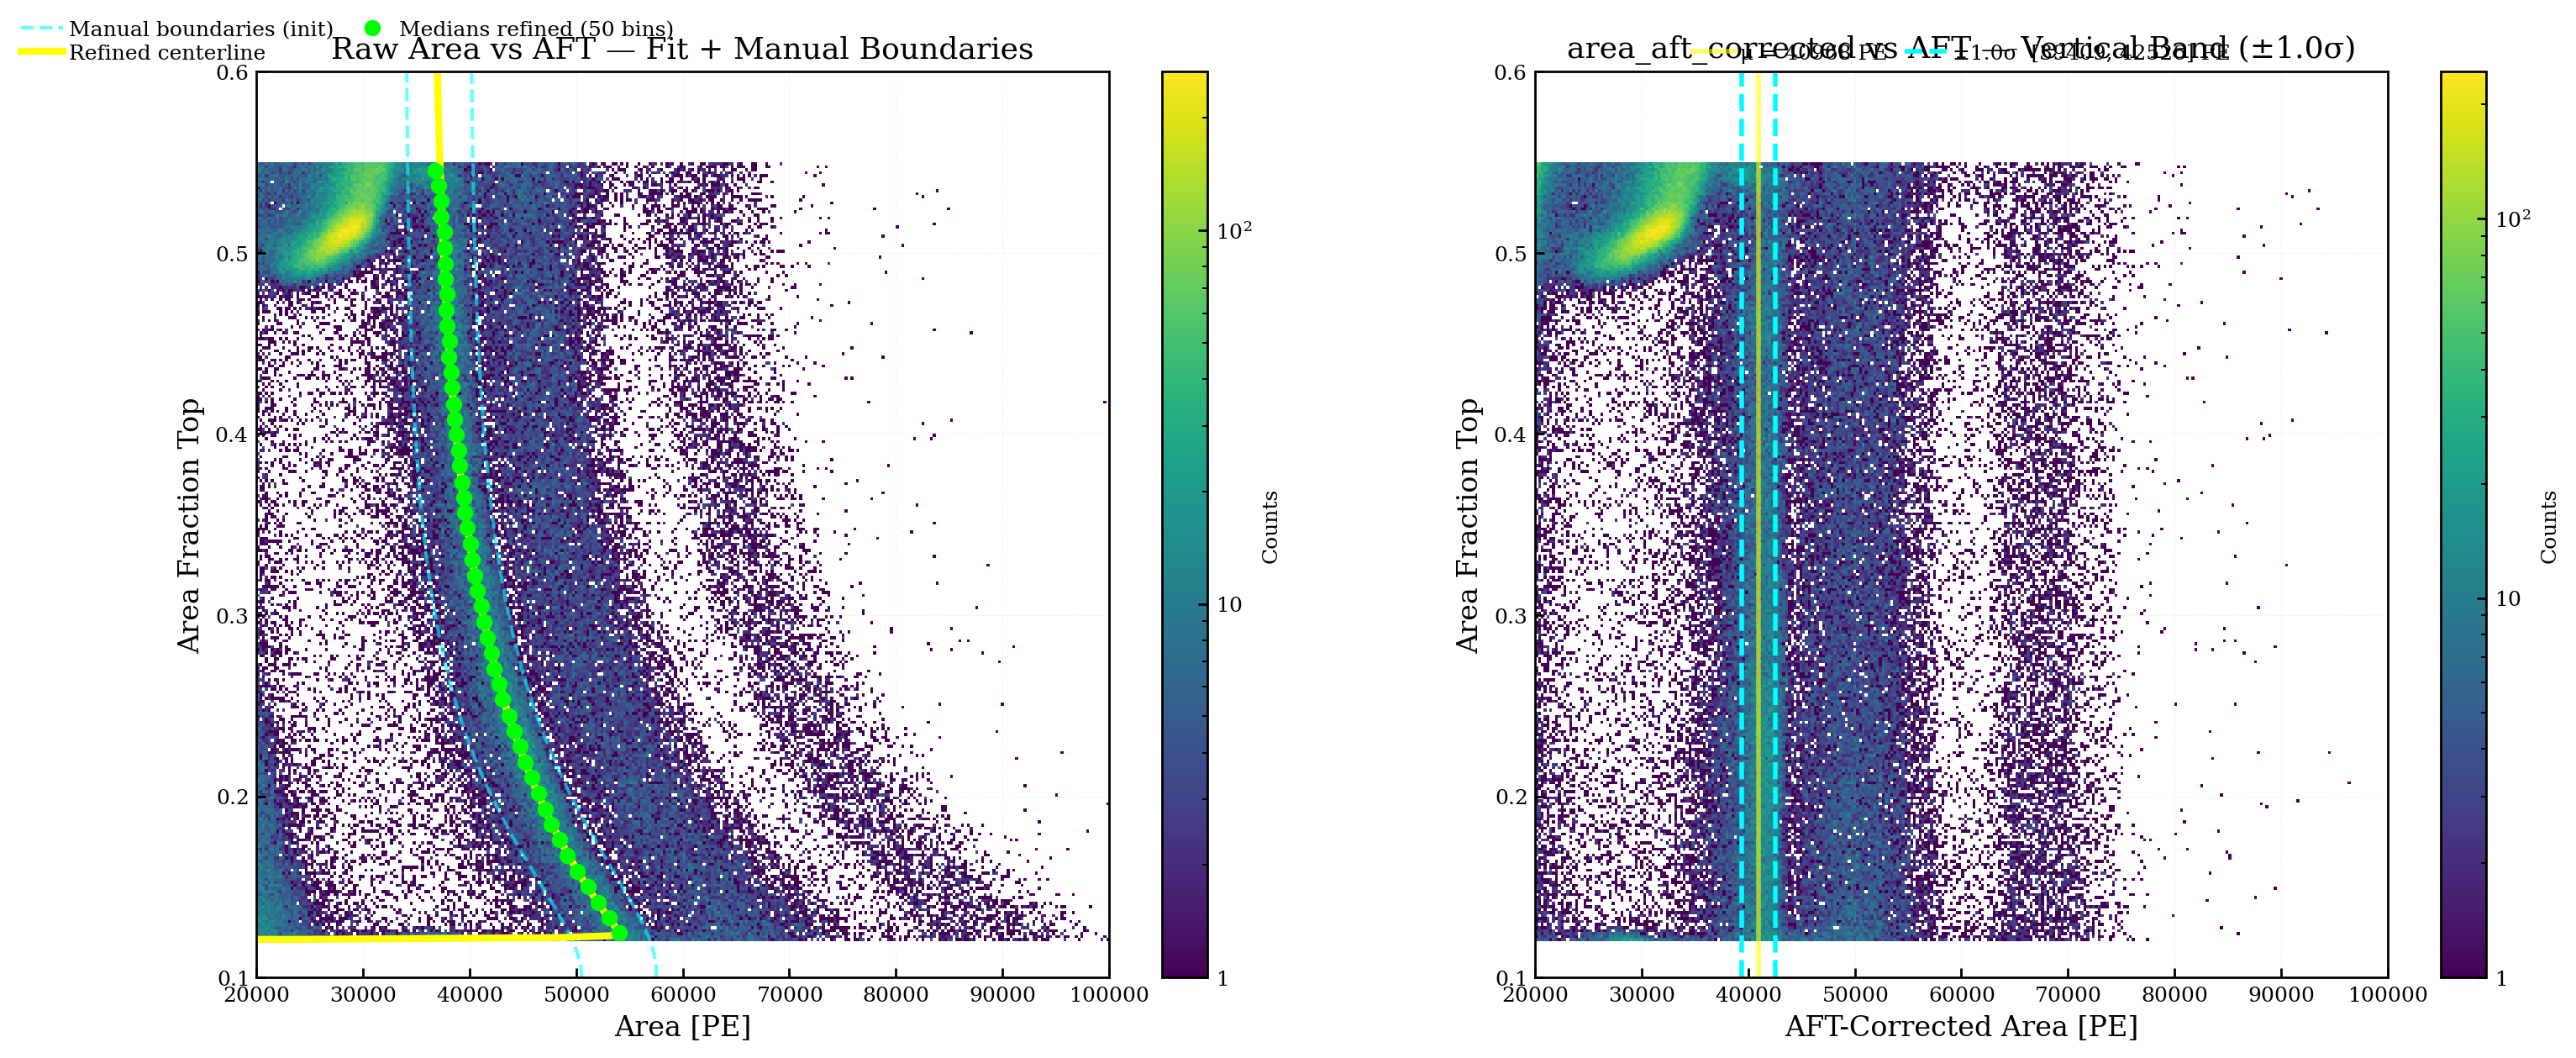


Rn band (vertical, ±1.0σ): [39409, 42526] PE
Reference AFT: 0.3


In [158]:
# ═══════════════════════════════════════════════════════════════
# CORRECTION 1a: Rn-222 Band Fitting in Area vs AFT
# ═══════════════════════════════════════════════════════════════
# Two-step process:
#   1. Initial fit using manual exp_bump_model boundaries
#   2. Refine: select Rn band as VERTICAL cut (±1σ) in area_aft_corrected,
#      re-fit exp_bump_model to the improved selection.
# Correction is applied to the FULL d_cor afterwards (in 1b).

d_cor = df_cut.copy()

# ── Fit region: restrict AFT to avoid edges ──
aft_fit_min, aft_fit_max = 0.12, 0.55
mask_fit_region = (
    (d_cor['area_fraction_top'] >= aft_fit_min) &
    (d_cor['area_fraction_top'] <= aft_fit_max)
)
d_fit = d_cor.loc[mask_fit_region].copy()
print(f'Events in fit AFT range [{aft_fit_min}, {aft_fit_max}]: {len(d_fit):,}')

# ═══════════════════════════════════════════════════════════════
# STEP 1: Initial fit with manual exp_bump_model boundaries
# ═══════════════════════════════════════════════════════════════

rn_upper_pars = [4.55e4, -4.88e-2, -0.1, -0.05, 40e3]
rn_lower_pars = [4.55e4, -4.88e-2, -0.09, -0.05, 34e3]

d_fit['in_rn_band_manual'] = (
    (d_fit['area'] < exp_bump_model(d_fit['area_fraction_top'], *rn_upper_pars)) &
    (d_fit['area'] > exp_bump_model(d_fit['area_fraction_top'], *rn_lower_pars))
)
print(f'Events in Rn band (manual boundaries): {d_fit["in_rn_band_manual"].sum():,}')

# ── Bin & fit (initial pass) ──
n_aft_bins = 50
aft_edges = np.linspace(aft_fit_min, aft_fit_max, n_aft_bins + 1)
d_fit['aft_bin'] = pd.cut(d_fit['area_fraction_top'], bins=aft_edges)

medians_rn_init = (
    d_fit[d_fit['in_rn_band_manual']]
    .groupby('aft_bin', observed=True)['area']
    .median()
)
aft_c_init = medians_rn_init.index.map(lambda iv: iv.mid).astype(float).values
m_vals_init = medians_rn_init.values
good_init = ~np.isnan(m_vals_init)
aft_c_init, m_vals_init = aft_c_init[good_init], m_vals_init[good_init]

p0_rn = [4.55e4, -0.05, -0.1, -0.05, 35e3]
p_opt_init, _ = curve_fit(
    exp_bump_model, aft_c_init, m_vals_init,
    p0=p0_rn,
    bounds=([0, -np.inf, -np.inf, -np.inf, 0], [np.inf, 0, 0, 0, np.inf]),
    maxfev=10000
)
print(f'Initial fit done.  a={p_opt_init[0]:.0f}  b={p_opt_init[1]:.4f}  '
      f'c={p_opt_init[2]:.4f}  d={p_opt_init[3]:.4f}  e={p_opt_init[4]:.0f}')

# ═══════════════════════════════════════════════════════════════
# STEP 2: Refine — vertical band in area_aft_corrected (±1σ)
# ═══════════════════════════════════════════════════════════════

aft_ref = 0.30
N_SIGMA = 1.0

# Compute initial area_aft_corrected for band definition
area_ref_init = exp_bump_model(aft_ref, *p_opt_init)
d_fit['area_aft_corrected_temp'] = (
    d_fit['area'] * area_ref_init
    / exp_bump_model(d_fit['area_fraction_top'], *p_opt_init)
)

# Find μ, σ of corrected area for initial Rn-band events
rn_init = d_fit[d_fit['in_rn_band_manual']]
mu_rn = rn_init['area_aft_corrected_temp'].mean()
sig_rn = rn_init['area_aft_corrected_temp'].std()

print(f'\nInitial Rn band in corrected space: μ = {mu_rn:.0f} PE, σ = {sig_rn:.0f} PE')
print(f'Vertical band (±{N_SIGMA}σ): [{mu_rn - N_SIGMA*sig_rn:.0f}, {mu_rn + N_SIGMA*sig_rn:.0f}] PE')

# Redefine Rn band as VERTICAL cut in area_aft_corrected
d_fit['in_rn_band'] = (
    abs(d_fit['area_aft_corrected_temp'] - mu_rn) < N_SIGMA * sig_rn
)
print(f'Events in Rn band (vertical ±{N_SIGMA}σ): {d_fit["in_rn_band"].sum():,}')

# ── Re-bin & re-fit with improved selection ──
medians_rn = (
    d_fit[d_fit['in_rn_band']]
    .groupby('aft_bin', observed=True)['area']
    .median()
)
aft_centers = medians_rn.index.map(lambda iv: iv.mid).astype(float).values
median_values = medians_rn.values
good_rn = ~np.isnan(median_values)
aft_c_rn, m_vals_rn = aft_centers[good_rn], median_values[good_rn]

print(f'AFT bins with Rn data (refined): {len(aft_c_rn)}')

# Fit exp_bump_model to refined medians
p_opt_rn, p_cov_rn = curve_fit(
    exp_bump_model, aft_c_rn, m_vals_rn,
    p0=p_opt_init,
    bounds=([0, -np.inf, -np.inf, -np.inf, 0], [np.inf, 0, 0, 0, np.inf]),
    maxfev=10000
)
p_err_rn = np.sqrt(np.diag(p_cov_rn))

print(f'\n=== Rn-222/220 BAND FIT (REFINED) ===')
for name, val, err in zip(['a','b','c','d','e'], p_opt_rn, p_err_rn):
    print(f'  {name} = {val:.6e} ± {err:.6e}')

# ── Store vertical band bounds for downstream use ──
rn_band_lo = mu_rn - N_SIGMA * sig_rn
rn_band_hi = mu_rn + N_SIGMA * sig_rn

# ═══════════════════════════════════════════════════════════════
# PLOT: 2-panel — (left) Raw Area vs AFT + fit  (right) area_aft_corrected vs AFT + vertical band
# ═══════════════════════════════════════════════════════════════

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
aft_fine = np.linspace(0.10, 0.60, 500)

# Left: Raw Area vs AFT with initial & refined fits
ax = axes[0]
h = ax.hist2d(
    d_fit['area'], d_fit['area_fraction_top'],
    bins=[300, 300], range=[[20e3, 100e3], [0.1, 0.6]],
    cmin=1, norm=matplotlib.colors.LogNorm()
)
cbar = plt.colorbar(h[3], ax=ax, label='Counts')
ax.plot(exp_bump_model(aft_fine, *rn_upper_pars), aft_fine,
        '--', color='cyan', lw=1.5, alpha=0.6, label='Manual boundaries (init)')
ax.plot(exp_bump_model(aft_fine, *rn_lower_pars), aft_fine,
        '--', color='cyan', lw=1.5, alpha=0.6)
ax.plot(exp_bump_model(aft_fine, *p_opt_rn), aft_fine,
        '-', color='yellow', lw=3, label='Refined centerline')
ax.plot(m_vals_rn, aft_c_rn, 'o', color='lime', markersize=6,
        label=f'Medians refined ({len(aft_c_rn)} bins)', zorder=5)
ax.set_xlabel('Area [PE]', fontsize=12)
ax.set_ylabel('Area Fraction Top', fontsize=12)
ax.set_title('Raw Area vs AFT — Fit + Manual Boundaries', fontsize=13)
ax.legend(fontsize=9, loc='lower right')
ax.grid(True, alpha=0.2)

# Right: AFT-corrected Area vs AFT with vertical band boundaries
ax = axes[1]
h = ax.hist2d(
    d_fit['area_aft_corrected_temp'], d_fit['area_fraction_top'],
    bins=[300, 300], range=[[20e3, 100e3], [0.1, 0.6]],
    cmin=1, norm=matplotlib.colors.LogNorm()
)
plt.colorbar(h[3], ax=ax, label='Counts')
ax.axvline(x=mu_rn, color='yellow', lw=2, alpha=0.6, label=f'μ = {mu_rn:.0f} PE')
ax.axvline(x=rn_band_lo, color='cyan', ls='--', lw=2,
           label=f'±{N_SIGMA}σ  [{rn_band_lo:.0f}, {rn_band_hi:.0f}] PE')
ax.axvline(x=rn_band_hi, color='cyan', ls='--', lw=2)
ax.set_xlabel('AFT-Corrected Area [PE]', fontsize=12)
ax.set_ylabel('Area Fraction Top', fontsize=12)
ax.set_title(f'area_aft_corrected vs AFT — Vertical Band (±{N_SIGMA}σ)', fontsize=13)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.2)

safe_tight(fig)
plt.show()

print(f'\nRn band (vertical, ±{N_SIGMA}σ): [{rn_band_lo:.0f}, {rn_band_hi:.0f}] PE')
print(f'Reference AFT: {aft_ref}')

Reference AFT: 0.3
Reference area (Rn centerline at AFT=0.3): 41329 PE
Rn band definition: area_aft_corrected ∈ [38629, 43306] PE (vertical, ±1.5σ)
AFT correction applied to 2,273,130 events (full dataset)
Rn-band events (vertical ±1.5σ): 42,712


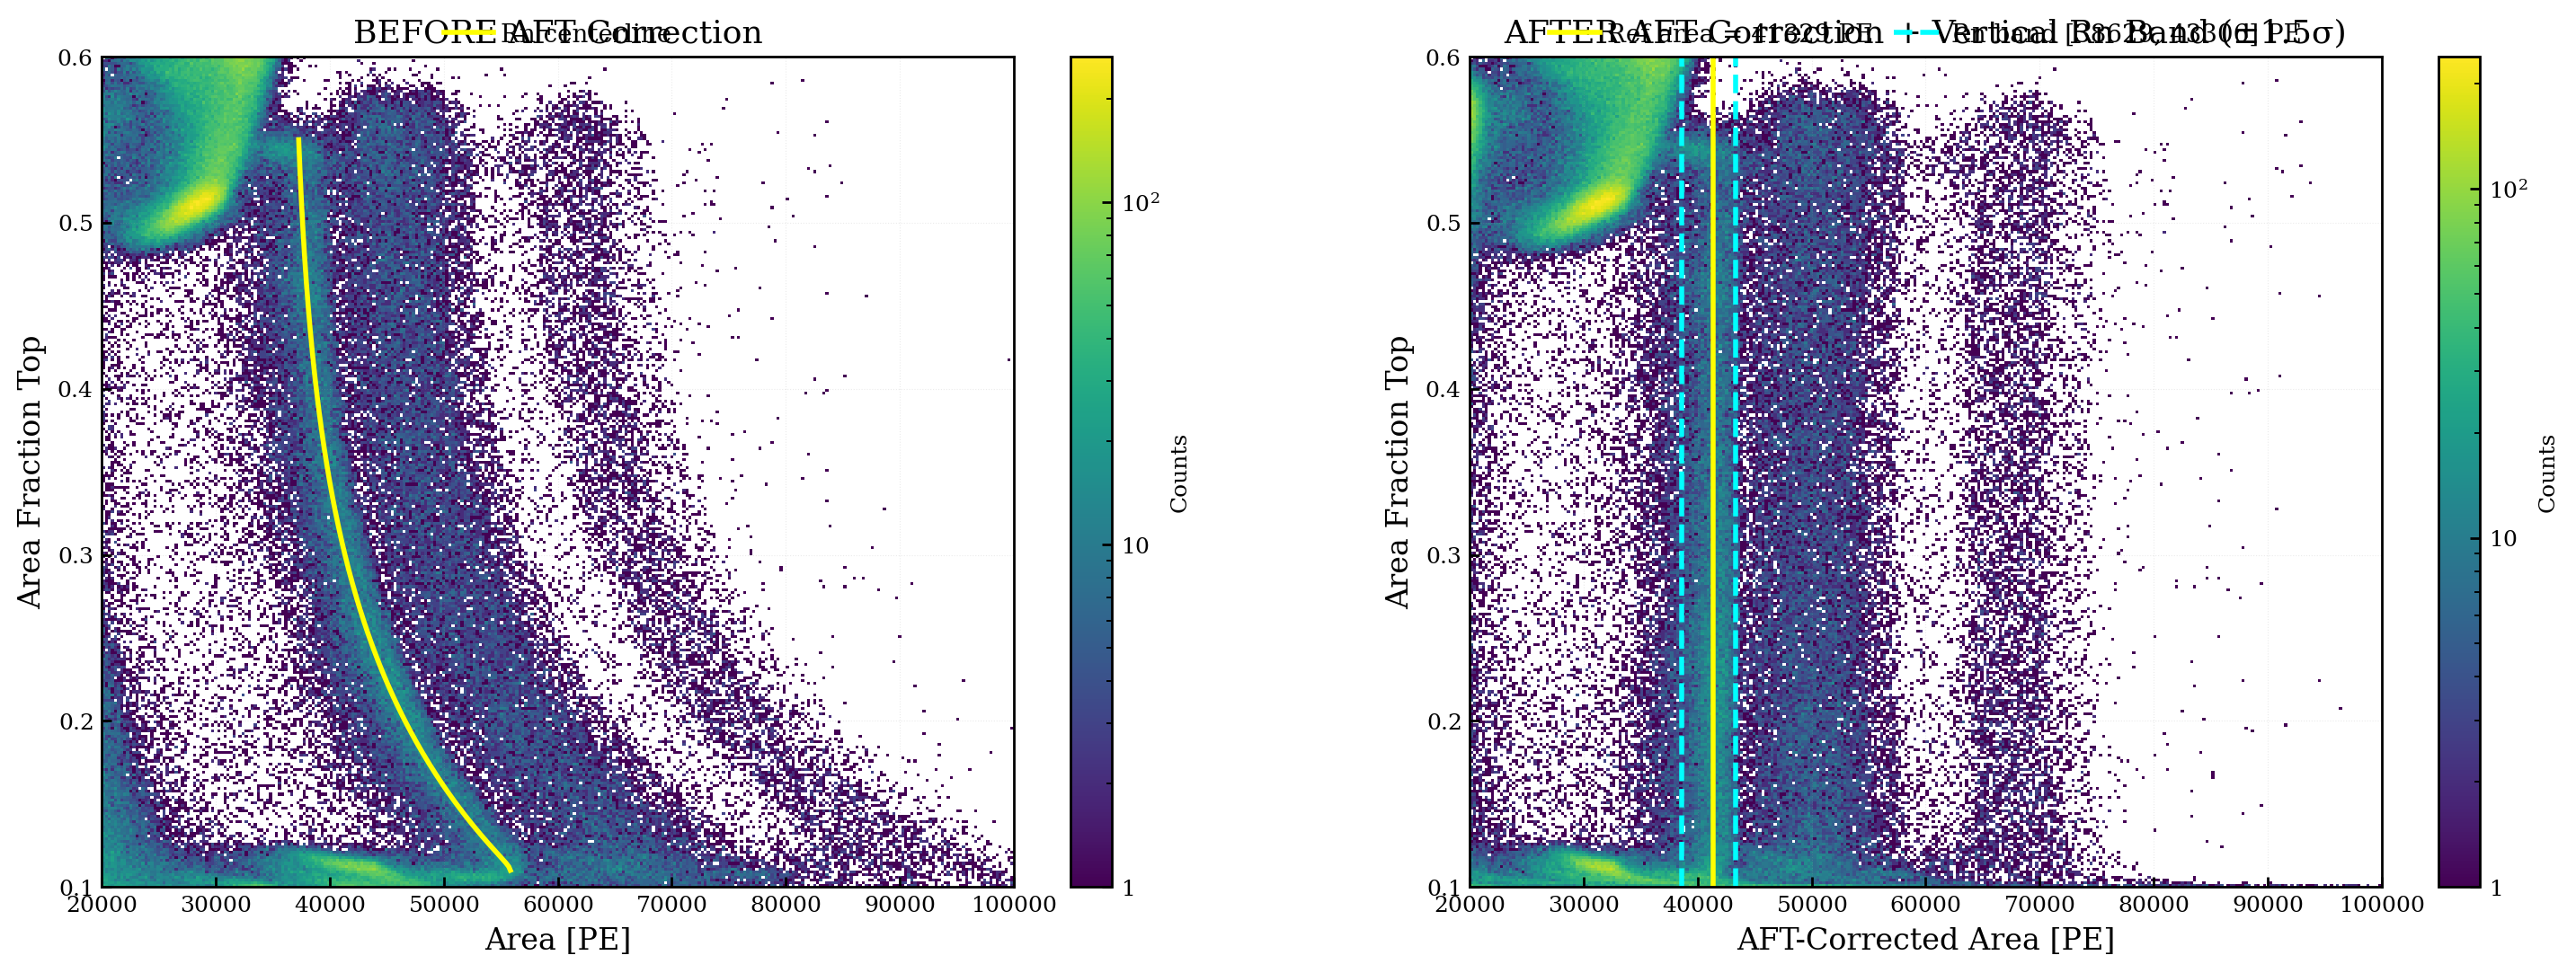

In [157]:
# ═══════════════════════════════════════════════════════════════
# CORRECTION 1b: Apply AFT Correction to FULL dataset
# ═══════════════════════════════════════════════════════════════
# Uses the REFINED centerline from Correction 1a.
# Tags Rn band as a VERTICAL cut in area_aft_corrected (±1σ).
# Applied to ALL of d_cor (not just the fit region).

area_ref = exp_bump_model(aft_ref, *p_opt_rn)

print(f'Reference AFT: {aft_ref}')
print(f'Reference area (Rn centerline at AFT={aft_ref}): {area_ref:.0f} PE')
print(f'Rn band definition: area_aft_corrected ∈ [{rn_band_lo:.0f}, {rn_band_hi:.0f}] PE (vertical, ±{N_SIGMA}σ)')

# Apply correction to full d_cor
d_cor['area_aft_corrected'] = (
    d_cor['area']
    * area_ref
    / exp_bump_model(d_cor['area_fraction_top'], *p_opt_rn)
)

# Tag Rn band in full d_cor — VERTICAL cut in area_aft_corrected
d_cor['in_rn_band'] = (
    (d_cor['area_aft_corrected'] >= rn_band_lo) &
    (d_cor['area_aft_corrected'] <= rn_band_hi)
)

print(f'AFT correction applied to {len(d_cor):,} events (full dataset)')
print(f'Rn-band events (vertical ±{N_SIGMA}σ): {d_cor["in_rn_band"].sum():,}')

# ── Before/After plot (shown in fit region for visibility) ──
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

mask_plot = (
    (d_cor['area_fraction_top'] >= 0.10) & (d_cor['area_fraction_top'] <= 0.60)
)
d_plot = d_cor.loc[mask_plot]

ax = axes[0]
h = ax.hist2d(d_plot['area'], d_plot['area_fraction_top'],
              bins=[300, 300], range=[[20e3, 100e3], [0.1, 0.6]],
              cmin=1, norm=matplotlib.colors.LogNorm())
plt.colorbar(h[3], ax=ax, label='Counts')
ax.plot(exp_bump_model(aft_fine, *p_opt_rn), aft_fine,
        '-', color='yellow', lw=2, label='Rn centerline')
ax.set_xlabel('Area [PE]', fontsize=12)
ax.set_ylabel('Area Fraction Top', fontsize=12)
ax.set_title('BEFORE AFT Correction', fontsize=13)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.2)

ax = axes[1]
h = ax.hist2d(d_plot['area_aft_corrected'], d_plot['area_fraction_top'],
              bins=[300, 300], range=[[20e3, 100e3], [0.1, 0.6]],
              cmin=1, norm=matplotlib.colors.LogNorm())
plt.colorbar(h[3], ax=ax, label='Counts')
ax.axvline(x=area_ref, color='yellow', lw=2, ls='-',
           label=f'Ref area = {area_ref:.0f} PE')
ax.axvline(x=rn_band_lo, color='cyan', ls='--', lw=2,
           label=f'Rn band [{rn_band_lo:.0f}, {rn_band_hi:.0f}] PE')
ax.axvline(x=rn_band_hi, color='cyan', ls='--', lw=2)
ax.set_xlabel('AFT-Corrected Area [PE]', fontsize=12)
ax.set_ylabel('Area Fraction Top', fontsize=12)
ax.set_title(f'AFTER AFT Correction + Vertical Rn Band (±{N_SIGMA}σ)', fontsize=13)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.2)

safe_tight(fig)
plt.show()

### Correction 2: AFT vs r²

Quantify the correlation between AFT (depth proxy) and r² (radial position).
Use **Rn-222 band events** (tagged `in_rn_band` in Correction 1) and fit in **AFT (x) vs r² (y)** space.
Fit `r²(AFT) =` degree-N polynomial, then correct **r²** to the reference AFT → `r2_aft_corrected`.

Fit range: AFT ∈ [0.11, 0.55], r² ∈ [0, 700] cm².

Rn-band events in fit region: 36,774
  AFT range: [0.110, 0.550]
  r² range:  [5.2, 678.9]
AFT bins with ≥20 events: 40
Median r² range: [51.1, 474.0] cm²

Degree-10 polynomial fit: r²(AFT)
  c₀ = 8926.18 ± 481.47
  c1 = -2.2156e+05 ± 1.7069e+04
  c2 = 2.5220e+06 ± 2.6249e+05
  c3 = -1.6587e+07 ± 2.3211e+06
  c4 = 6.7151e+07 ± 1.3190e+07
  c5 = -1.6456e+08 ± 5.0882e+07
  ... (total 11 coefficients)


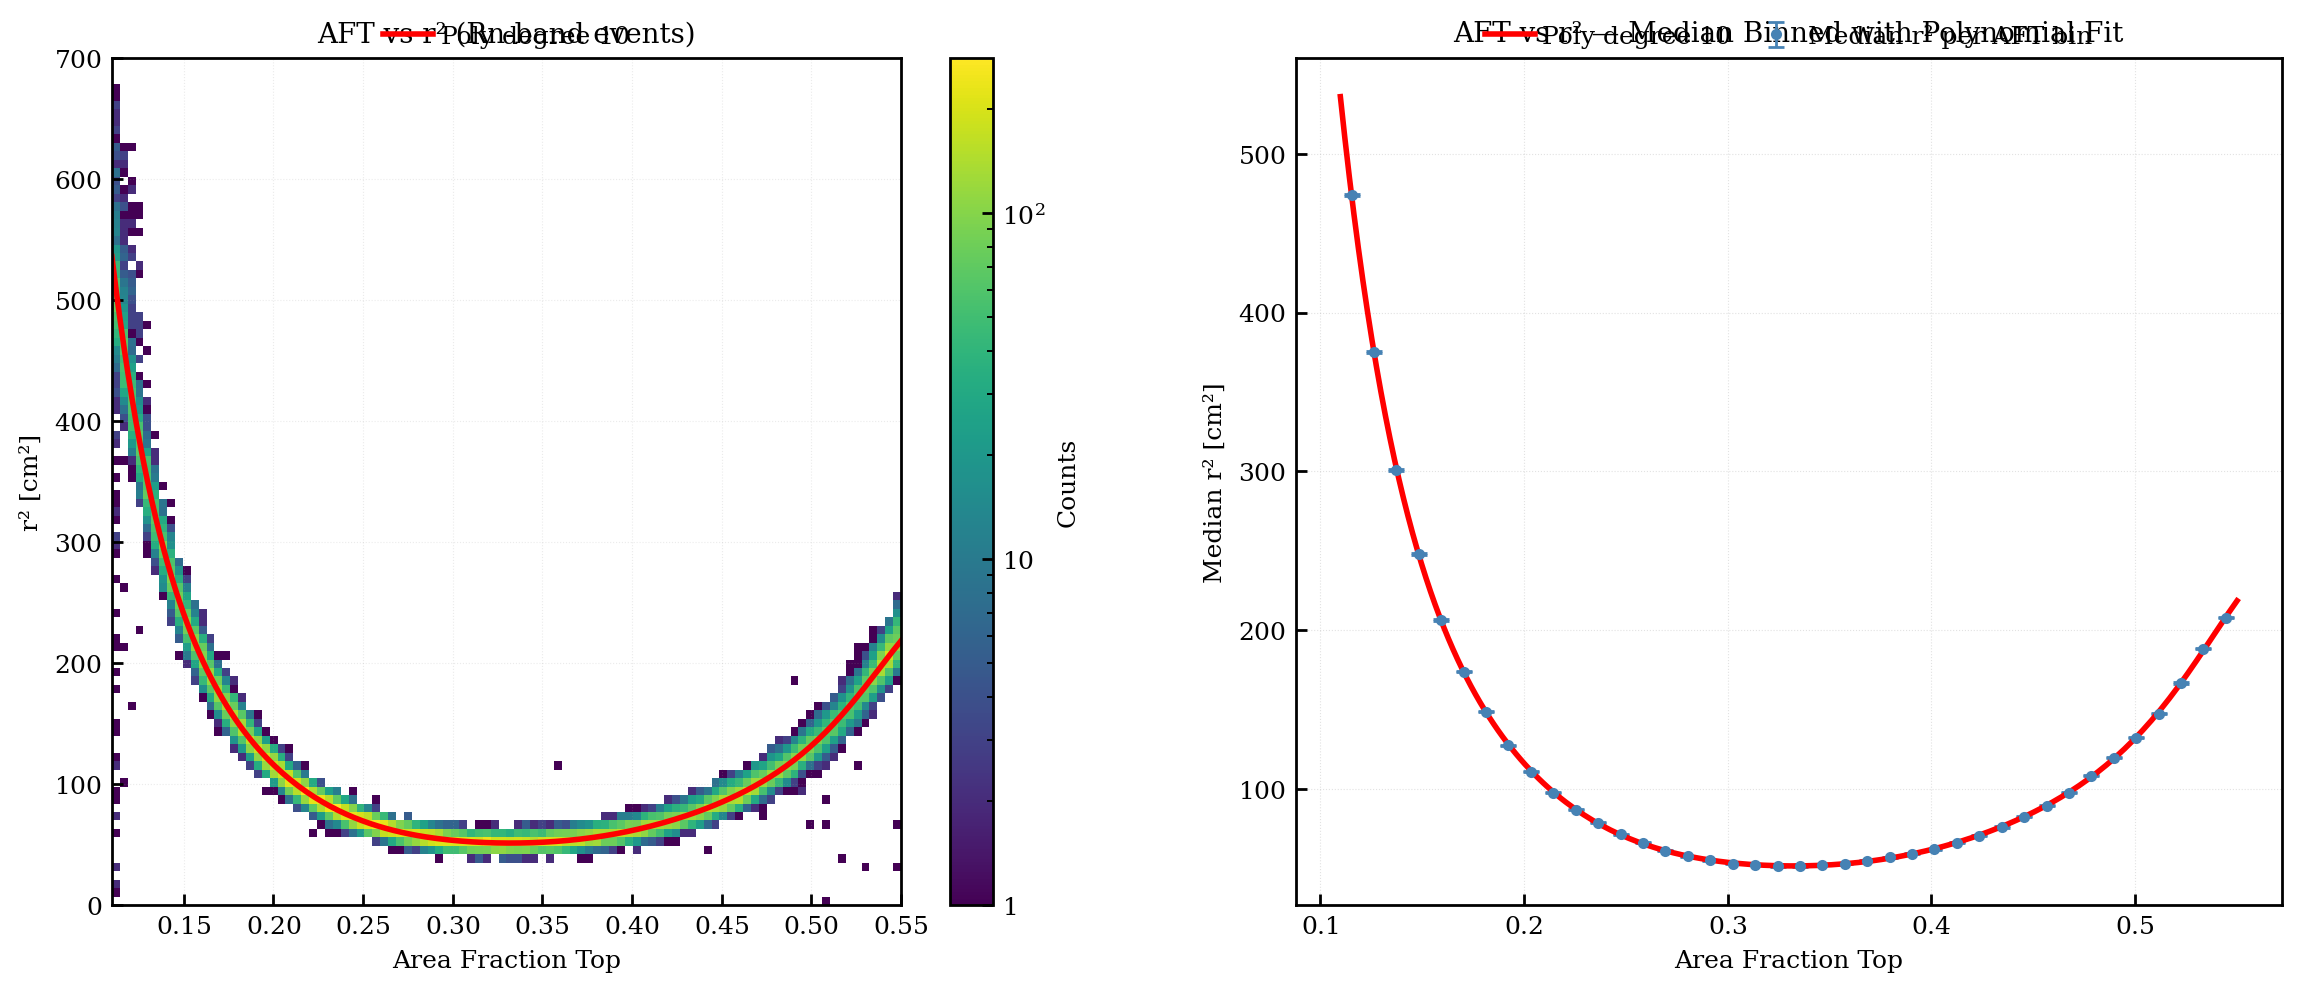


Reference AFT: 0.3
Expected r² at AFT=0.3: 53.6 cm²
Correction 2 factor range: [-11364.0577, 44496.4091]
Correction 2 applied to all 2,273,130 events — new column: r2_aft_corrected


In [156]:
# ═══════════════════════════════════════════════════════════════
# CORRECTION 2: AFT vs r² — polynomial fit + correction
# ═══════════════════════════════════════════════════════════════
# Plot and fit in AFT (x) vs r² (y) space.
# Use only Rn-222 band events tagged in Correction 1 (in_rn_band).
# Fit: r²(AFT) = degree-N polynomial, then correct r² using the
# fitted function (just like Correction 1 but for r² instead of area).

aft_min, aft_max = 0.11, 0.55
r2_min_aft, r2_max_aft = 0, 700
POLY_DEG = 10

# ── Select Rn-band events only ──
mask_r2aft = (
    (d_cor['r2'] >= r2_min_aft) & (d_cor['r2'] <= r2_max_aft) &
    (d_cor['area_fraction_top'] >= aft_min) & (d_cor['area_fraction_top'] <= aft_max) &
    (d_cor['in_rn_band'])
)
d_r2aft = d_cor.loc[mask_r2aft].copy()
print(f'Rn-band events in fit region: {len(d_r2aft):,}')
print(f'  AFT range: [{d_r2aft["area_fraction_top"].min():.3f}, {d_r2aft["area_fraction_top"].max():.3f}]')
print(f'  r² range:  [{d_r2aft["r2"].min():.1f}, {d_r2aft["r2"].max():.1f}]')

# ── Bin in AFT (x-axis), get median r² (y-axis) ──
n_aft_bins = 40
aft_edges = np.linspace(aft_min, aft_max, n_aft_bins + 1)
d_r2aft['aft_bin'] = pd.cut(d_r2aft['area_fraction_top'], bins=aft_edges)

medians_r2 = d_r2aft.groupby('aft_bin', observed=True)['r2'].median()
counts_r2  = d_r2aft.groupby('aft_bin', observed=True)['r2'].count()

aft_c = medians_r2.index.map(lambda iv: iv.mid).astype(float).values
r2_medians = medians_r2.values
good_bins = counts_r2.values >= 20

aft_fit_pts = aft_c[good_bins]
r2_fit_pts  = r2_medians[good_bins]
n_fit        = counts_r2.values[good_bins]

print(f'AFT bins with ≥20 events: {len(aft_fit_pts)}')
print(f'Median r² range: [{r2_fit_pts.min():.1f}, {r2_fit_pts.max():.1f}] cm²')

# ── Fit: r²(AFT) = degree-N polynomial ──
p0_poly = [np.median(r2_fit_pts)] + [0.0] * POLY_DEG
popt_r2, pcov_r2 = curve_fit(polynomial, aft_fit_pts, r2_fit_pts, p0=p0_poly, maxfev=50000)
perr_r2 = np.sqrt(np.diag(pcov_r2))

print(f'\nDegree-{POLY_DEG} polynomial fit: r²(AFT)')
print(f'  c₀ = {popt_r2[0]:.2f} ± {perr_r2[0]:.2f}')
for i in range(1, min(6, POLY_DEG + 1)):
    print(f'  c{i} = {popt_r2[i]:.4e} ± {perr_r2[i]:.4e}')
print(f'  ... (total {POLY_DEG + 1} coefficients)')

# ── Plot ──
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Left: 2D histogram — AFT (x) vs r² (y), Rn-band only
ax = axes[0]
h = ax.hist2d(d_r2aft['area_fraction_top'], d_r2aft['r2'],
              bins=[100, 100],
              range=[[aft_min, aft_max], [r2_min_aft, r2_max_aft]],
              cmin=1, norm=matplotlib.colors.LogNorm())
plt.colorbar(h[3], ax=ax, label='Counts')
aft_fine = np.linspace(aft_min, aft_max, 200)
ax.plot(aft_fine, polynomial(aft_fine, *popt_r2), 'r-', lw=2, label=f'Poly degree {POLY_DEG}')
ax.set_xlabel('Area Fraction Top')
ax.set_ylabel('r² [cm²]')
ax.set_title('AFT vs r² (Rn-band events)')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.2)

# Right: Median r² vs AFT with fit
ax = axes[1]
ax.errorbar(aft_fit_pts, r2_fit_pts,
            yerr=np.sqrt(np.maximum(r2_fit_pts, 1))/np.sqrt(n_fit),
            fmt='o', capsize=3, color='steelblue', label='Median r² per AFT bin')
ax.plot(aft_fine, polynomial(aft_fine, *popt_r2), 'r-', lw=2, label=f'Poly degree {POLY_DEG}')
ax.set_xlabel('Area Fraction Top')
ax.set_ylabel('Median r² [cm²]')
ax.set_title('AFT vs r² — Median Binned with Polynomial Fit')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

safe_tight(fig)
plt.show()

# ═══════════════════════════════════════════════════════════════
# APPLY CORRECTION 2: correct r² against AFT (ALL events)
# ═══════════════════════════════════════════════════════════════
# Normalize r² to the reference AFT using the fitted polynomial.
# No clipping — the polynomial is well-behaved and the large
# correction factors at AFT edges are physically expected.
#
#   r2_aft_corrected = r² * r2_at_ref / poly(AFT)

r2_at_ref_aft = polynomial(aft_ref, *popt_r2)   # expected r² at reference AFT
print(f'\nReference AFT: {aft_ref}')
print(f'Expected r² at AFT={aft_ref}: {r2_at_ref_aft:.1f} cm²')

cf_r2aft = r2_at_ref_aft / polynomial(d_cor['area_fraction_top'].values, *popt_r2)

d_cor['r2_aft_corrected'] = d_cor['r2'] * cf_r2aft
d_cor['corr2_factor'] = cf_r2aft

print(f'Correction 2 factor range: [{cf_r2aft.min():.4f}, {cf_r2aft.max():.4f}]')
print(f'Correction 2 applied to all {len(d_cor):,} events — new column: r2_aft_corrected')

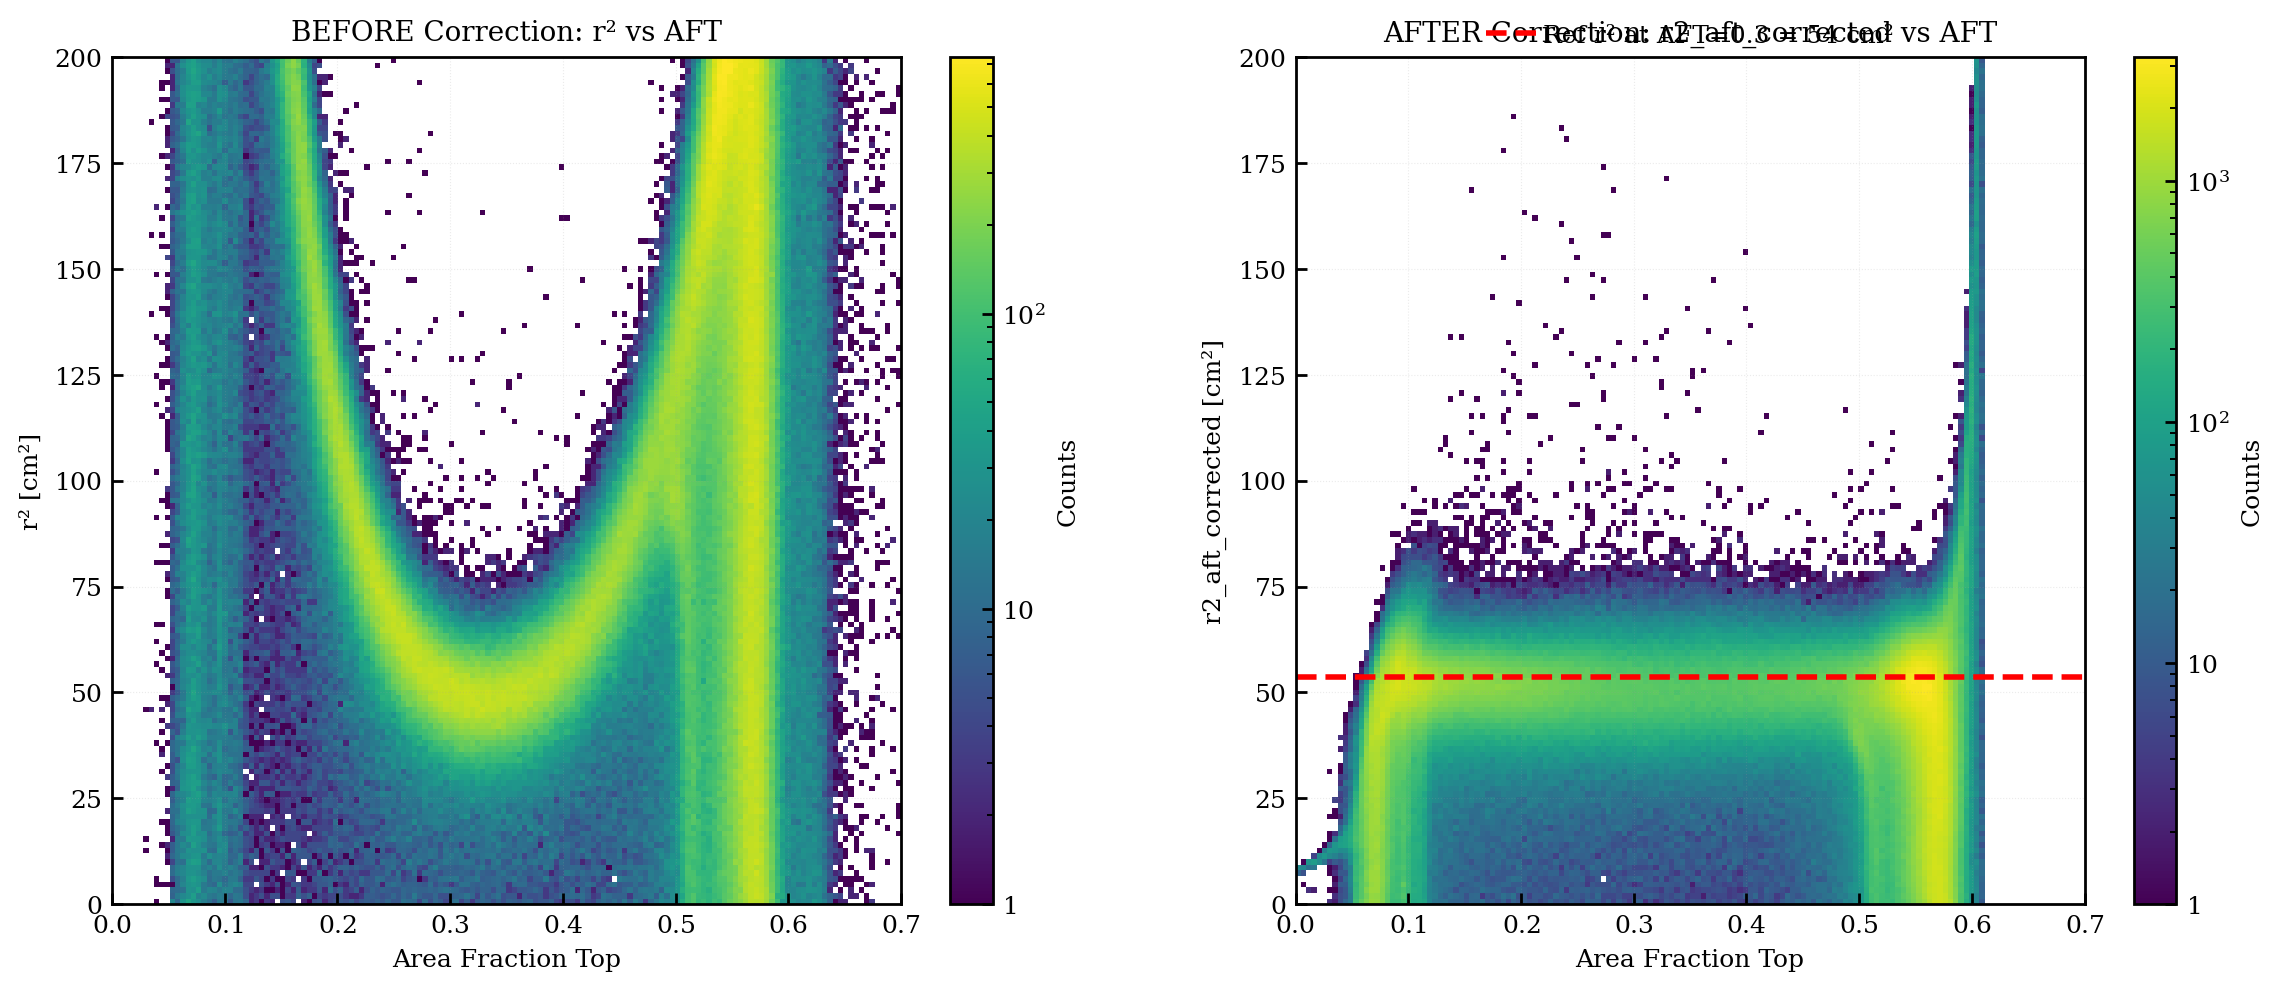

Correction 2 diagnostic:
  Raw r² mean: 259.4 cm²
  r2_aft_corrected mean: 45.7 cm²
  Reference r² at AFT=0.3: 54 cm²


In [155]:
# ═══════════════════════════════════════════════════════════════
# CORRECTION 2 DIAGNOSTIC: r2_aft_corrected vs AFT
# ═══════════════════════════════════════════════════════════════
# Verify that the r² correction removes AFT dependence.

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Left: BEFORE — raw r² vs AFT
ax = axes[0]
h = ax.hist2d(d_cor['area_fraction_top'], d_cor['r2'],
              bins=[150, 150],
              range=[[0, 0.7], [0, 200]],
              cmin=1, norm=matplotlib.colors.LogNorm())
plt.colorbar(h[3], ax=ax, label='Counts')
ax.set_xlabel('Area Fraction Top')
ax.set_ylabel('r² [cm²]')
ax.set_title('BEFORE Correction: r² vs AFT')
ax.grid(True, alpha=0.2)

# Right: AFTER — r2_aft_corrected vs AFT
ax = axes[1]
h = ax.hist2d(d_cor['area_fraction_top'], d_cor['r2_aft_corrected'],
              bins=[150, 150],
              range=[[0, 0.7], [0, 200]],
              cmin=1, norm=matplotlib.colors.LogNorm())
plt.colorbar(h[3], ax=ax, label='Counts')
ax.axhline(y=r2_at_ref_aft, color='red', ls='--', lw=2,
           label=f'Ref r² at AFT={aft_ref} = {r2_at_ref_aft:.0f} cm²')
ax.set_xlabel('Area Fraction Top')
ax.set_ylabel('r2_aft_corrected [cm²]')
ax.set_title('AFTER Correction: r2_aft_corrected vs AFT')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.2)

safe_tight(fig)
plt.show()

print(f'Correction 2 diagnostic:')
print(f'  Raw r² mean: {d_cor["r2"].mean():.1f} cm²')
print(f'  r2_aft_corrected mean: {d_cor["r2_aft_corrected"].mean():.1f} cm²')
print(f'  Reference r² at AFT={aft_ref}: {r2_at_ref_aft:.0f} cm²')

### Correction 3: r² vs Area

Fit `area_aft_corrected` vs `r2_aft_corrected`. Select a band with **linear boundaries**
(area = k·r² + intercept, k = -0.2), fit degree-10 polynomial to the band centerline,
then correct area against r² → `area_2_corrected`.

X-axis: `r2_aft_corrected` (from Correction 2), Y-axis: `area_aft_corrected` (from Correction 1).

Fit range: r2_aft_corrected ∈ [0, 100] cm², area ∈ [0, 1e5] PE.

Events in fit range: 1,825,082
Events in linear band (k=-120): 9,239
r² bins with ≥10 band events & r² < 60: 18
Median area range: 64690 – 71413 PE

Degree-5 polynomial fit: area(r2_aft_corrected)  [r² < 60]
  c₀ = 71293 ± 224 PE
  c1 = 3.0531e+01 ± 7.5993e+01
  c2 = -1.4208e+01 ± 7.8046e+00
  c3 = 6.9962e-01 ± 3.2874e-01
  c4 = -1.5386e-02 ± 6.0337e-03
  c5 = 1.1743e-04 ± 4.0039e-05
  ... (total 6 coefficients)
  Reference area (r2_aft_corrected=0) = 71293 PE
Correction 3 factor range: [0.5000, 2.0000]
  Clipped 56095 values to [0.5, 2.0]
Correction 3 applied — new column: area_2_corrected


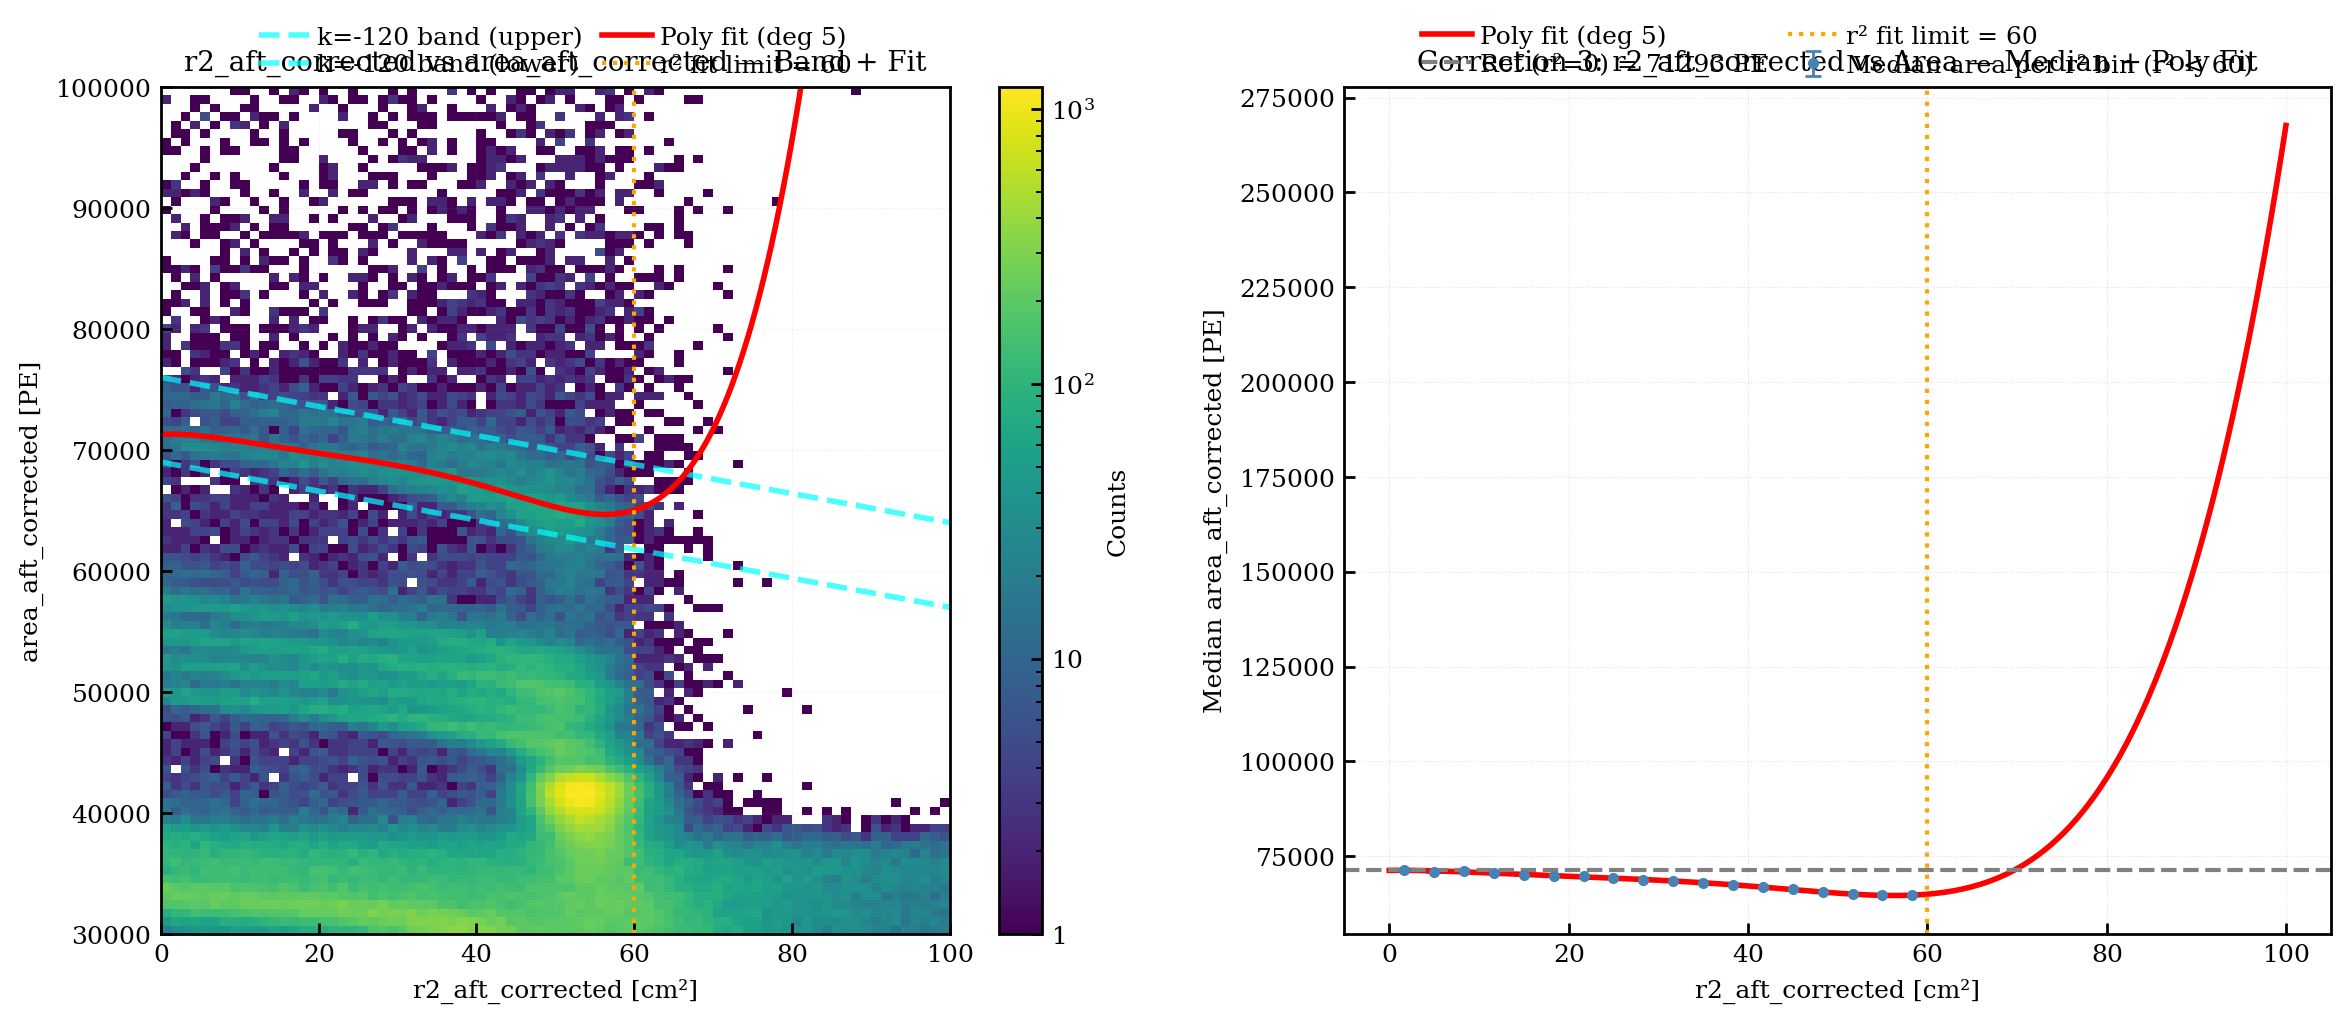

In [153]:
# ═══════════════════════════════════════════════════════════════
# CORRECTION 3a: r² vs Area — band selection + polynomial fit
# ═══════════════════════════════════════════════════════════════
# Fit AFT-corrected area vs AFT-corrected r².
# Select band with LINEAR boundaries, fit degree-5 polynomial
# to the band centerline using ONLY r² < 60.
#
# X-axis: r2_aft_corrected  (from Correction 2)
# Y-axis: area_aft_corrected (from Correction 1)
# Output: area_2_corrected   (AFT + r² corrected)
#
# Fit range: r2_aft_corrected ∈ [0, 100], area ∈ [0, 1e5]

r2_min_area, r2_max_area = 0, 100
R2_FIT_MAX = 60          # only fit using r² < 60 within the band
POLY_DEG_R2 = 5

# ── Linear band boundaries in r2_aft_corrected vs area_aft_corrected ──
# area = k * r2_aft_corrected + intercept
BAND_K = -120
BAND_INTERCEPT_UPPER = 76000
BAND_INTERCEPT_LOWER = 69000

# Select events in the fit range
mask_r2area = (
    (d_cor['r2_aft_corrected'] >= r2_min_area) & (d_cor['r2_aft_corrected'] <= r2_max_area) &
    (d_cor['area_aft_corrected'] >= 0) & (d_cor['area_aft_corrected'] <= 1e5)
)
d_r2area = d_cor.loc[mask_r2area].copy()

# Tag events inside the linear band
d_r2area['in_r2_band'] = (
    (d_r2area['area_aft_corrected'] < BAND_K * d_r2area['r2_aft_corrected'] + BAND_INTERCEPT_UPPER) &
    (d_r2area['area_aft_corrected'] > BAND_K * d_r2area['r2_aft_corrected'] + BAND_INTERCEPT_LOWER)
)

print(f'Events in fit range: {len(d_r2area):,}')
print(f'Events in linear band (k={BAND_K}): {d_r2area["in_r2_band"].sum():,}')

# ── Bin band events in r2_aft_corrected, get median area_aft_corrected ──
n_r2_bins_area = 30
r2_edges_area = np.linspace(r2_min_area, r2_max_area, n_r2_bins_area + 1)
d_r2area['r2_bin'] = pd.cut(d_r2area['r2_aft_corrected'], bins=r2_edges_area)

medians_area = (
    d_r2area[d_r2area['in_r2_band']]
    .groupby('r2_bin', observed=True)['area_aft_corrected']
    .median()
)
counts_area = (
    d_r2area[d_r2area['in_r2_band']]
    .groupby('r2_bin', observed=True)['area_aft_corrected']
    .count()
)

r2_c_area = medians_area.index.map(lambda iv: iv.mid).astype(float).values
area_meds = medians_area.values

# ── Select bins for fitting: ≥10 events AND r² < R2_FIT_MAX ──
good_area = (counts_area.values >= 10) & (r2_c_area < R2_FIT_MAX)

r2_fit_area = r2_c_area[good_area]
a_fit = area_meds[good_area]
n_fit_area = counts_area.values[good_area]

print(f'r² bins with ≥10 band events & r² < {R2_FIT_MAX}: {len(r2_fit_area)}')
print(f'Median area range: {a_fit.min():.0f} – {a_fit.max():.0f} PE')

# ── Fit degree-N polynomial: area = poly(r2_aft_corrected) ──
p0_r2area = [np.median(a_fit)] + [0.0] * POLY_DEG_R2
popt_r2area, pcov_r2area = curve_fit(polynomial, r2_fit_area, a_fit,
                                      p0=p0_r2area, maxfev=50000)
perr_r2area = np.sqrt(np.diag(pcov_r2area))

print(f'\nDegree-{POLY_DEG_R2} polynomial fit: area(r2_aft_corrected)  [r² < {R2_FIT_MAX}]')
print(f'  c₀ = {popt_r2area[0]:.0f} ± {perr_r2area[0]:.0f} PE')
for i in range(1, min(6, POLY_DEG_R2 + 1)):
    print(f'  c{i} = {popt_r2area[i]:.4e} ± {perr_r2area[i]:.4e}')
print(f'  ... (total {POLY_DEG_R2 + 1} coefficients)')

area_ref_r2 = polynomial(0, *popt_r2area)
print(f'  Reference area (r2_aft_corrected=0) = {area_ref_r2:.0f} PE')

# ── Apply correction: normalize area to r2_aft_corrected=0 ──
cf_r2_raw = area_ref_r2 / polynomial(d_cor['r2_aft_corrected'].values, *popt_r2area)
cf_r2 = np.clip(cf_r2_raw, 0.5, 2.0)

d_cor['area_2_corrected'] = d_cor['area_aft_corrected'] * cf_r2
d_cor['corr3_factor'] = cf_r2

n_clipped_r2 = (cf_r2_raw != cf_r2).sum()
print(f'Correction 3 factor range: [{cf_r2.min():.4f}, {cf_r2.max():.4f}]')
if n_clipped_r2 > 0:
    print(f'  Clipped {n_clipped_r2} values to [0.5, 2.0]')
print(f'Correction 3 applied — new column: area_2_corrected')

# ── Plot ──
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Left: 2D histogram with band boundaries and fit
ax = axes[0]
h = ax.hist2d(d_r2area['r2_aft_corrected'], d_r2area['area_aft_corrected'],
              bins=[80, 100],
              range=[[r2_min_area, r2_max_area], [30e3, 100e3]],
              cmin=1, norm=matplotlib.colors.LogNorm())
plt.colorbar(h[3], ax=ax, label='Counts')

r2_fine_area = np.linspace(r2_min_area, r2_max_area, 200)
ax.plot(r2_fine_area, BAND_K * r2_fine_area + BAND_INTERCEPT_UPPER,
        '--', color='cyan', lw=2, alpha=0.7, label=f'k={BAND_K} band (upper)')
ax.plot(r2_fine_area, BAND_K * r2_fine_area + BAND_INTERCEPT_LOWER,
        '--', color='cyan', lw=2, alpha=0.7, label=f'k={BAND_K} band (lower)')
ax.plot(r2_fine_area, polynomial(r2_fine_area, *popt_r2area),
        'r-', lw=2, label=f'Poly fit (deg {POLY_DEG_R2})')
ax.axvline(x=R2_FIT_MAX, color='orange', ls=':', lw=1.5,
           label=f'r² fit limit = {R2_FIT_MAX}')
ax.set_xlabel('r2_aft_corrected [cm²]')
ax.set_ylabel('area_aft_corrected [PE]')
ax.set_title('r2_aft_corrected vs area_aft_corrected — Band + Fit')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.2)

# Right: Median binned with fit
ax = axes[1]
ax.errorbar(r2_fit_area, a_fit,
            yerr=np.sqrt(np.maximum(a_fit, 1))/np.sqrt(n_fit_area),
            fmt='o', capsize=3, color='steelblue',
            label=f'Median area per r² bin (r² < {R2_FIT_MAX})')
ax.plot(r2_fine_area, polynomial(r2_fine_area, *popt_r2area),
        'r-', lw=2, label=f'Poly fit (deg {POLY_DEG_R2})')
ax.axhline(area_ref_r2, color='gray', ls='--', lw=1.5,
           label=f'Ref (r²=0) = {area_ref_r2:.0f} PE')
ax.axvline(x=R2_FIT_MAX, color='orange', ls=':', lw=1.5,
           label=f'r² fit limit = {R2_FIT_MAX}')
ax.set_xlabel('r2_aft_corrected [cm²]')
ax.set_ylabel('Median area_aft_corrected [PE]')
ax.set_title('Correction 3: r2_aft_corrected vs Area — Median + Poly Fit')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

safe_tight(fig)
plt.show()

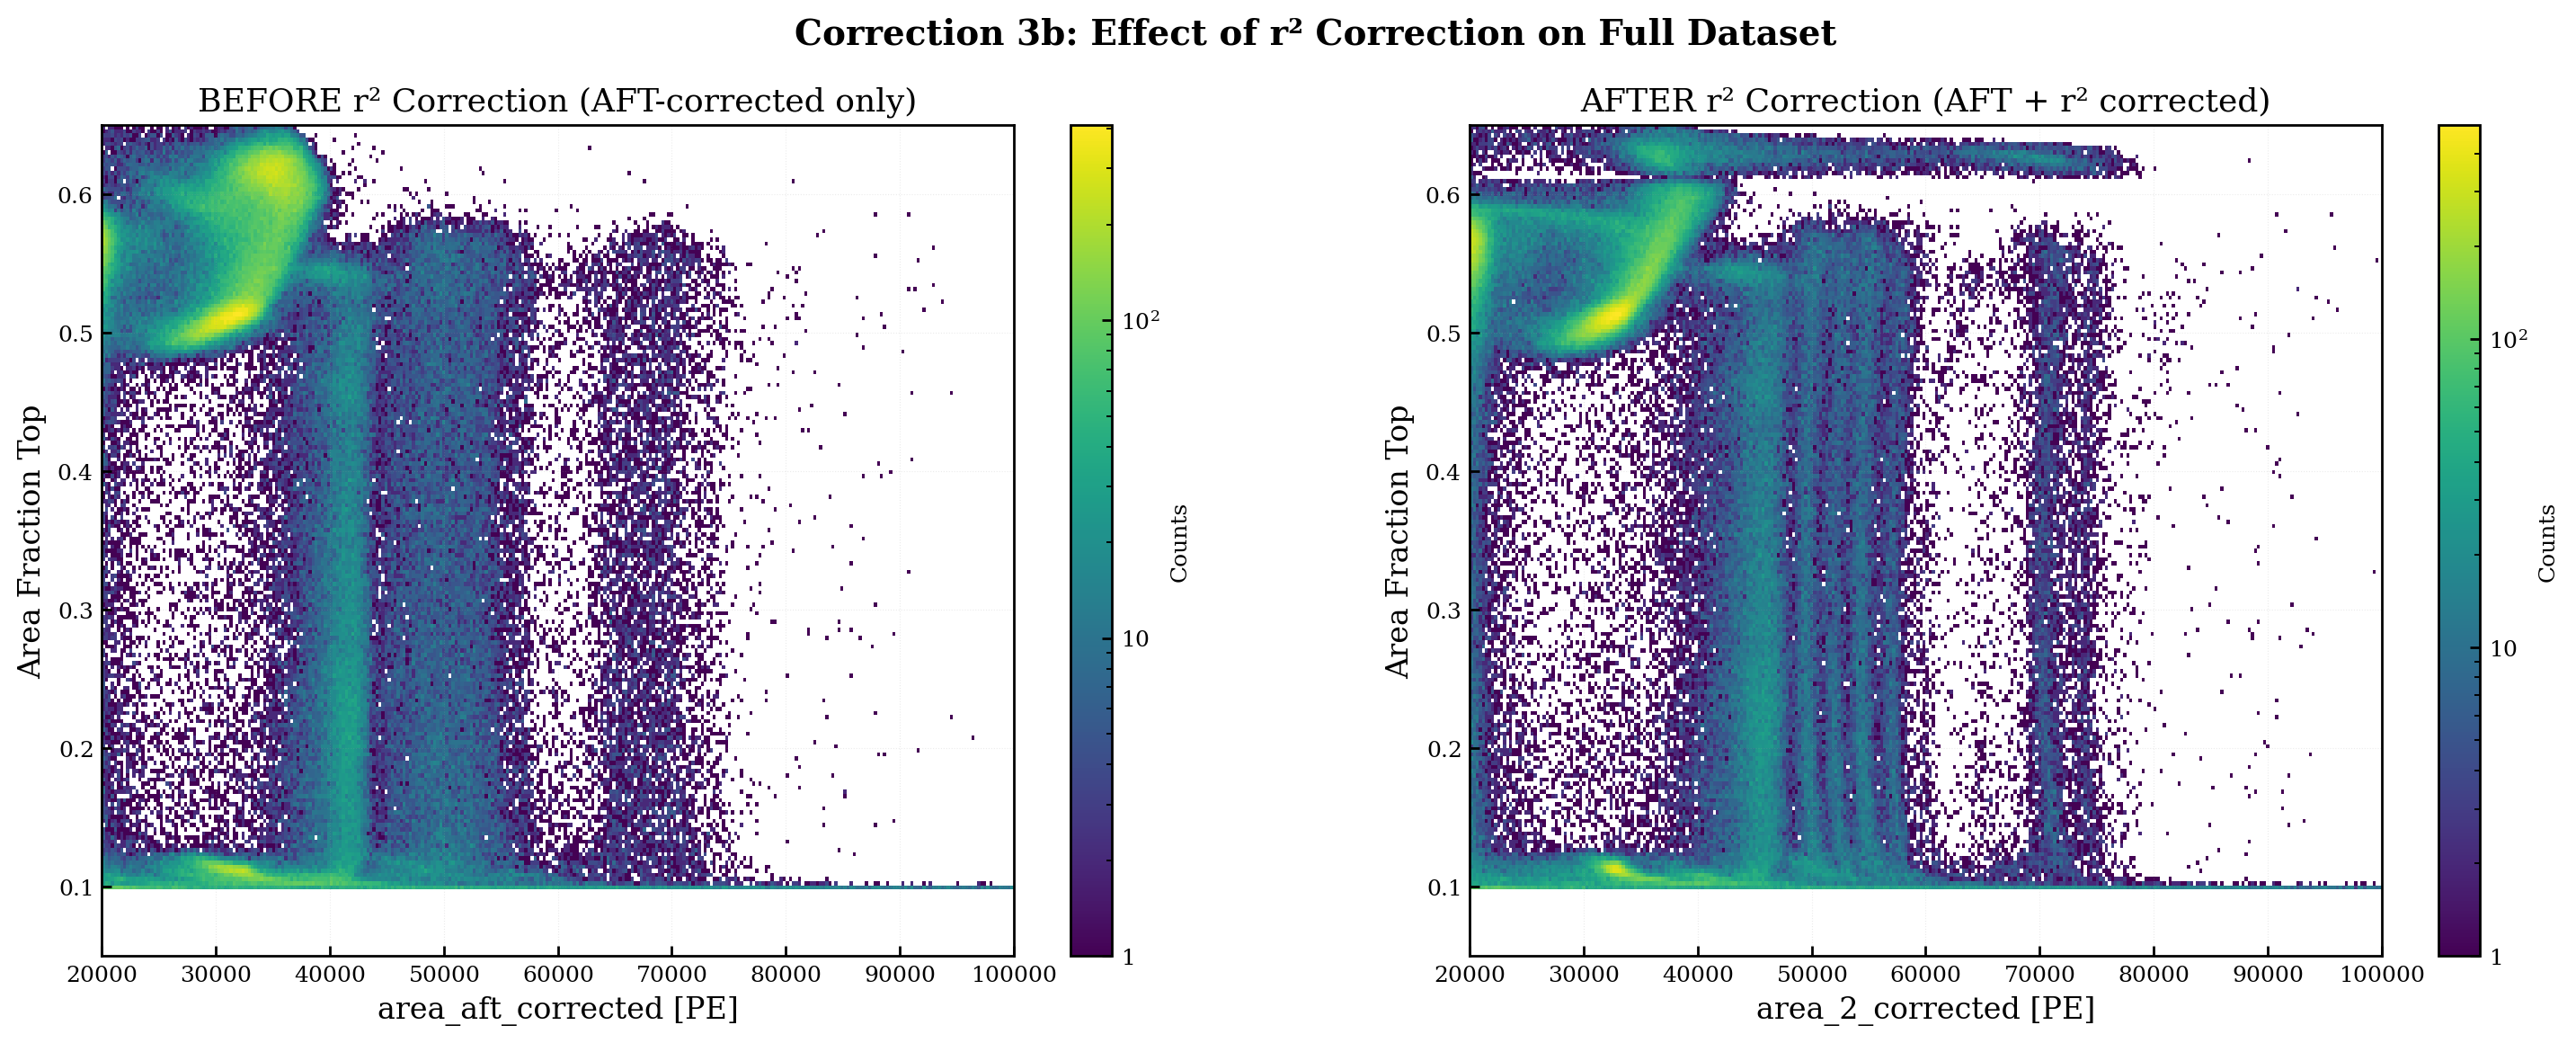

Correction 3b summary:
  area_aft_corrected  μ=12759  σ=1006092 PE
  area_2_corrected    μ=13172  σ=1072624 PE
  Correction applied to all 2,273,130 events


In [152]:
# ═══════════════════════════════════════════════════════════════
# CORRECTION 3b: Before/After — r² correction applied to ALL events
# ═══════════════════════════════════════════════════════════════

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Left: BEFORE — area_aft_corrected vs AFT
ax = axes[0]
h = ax.hist2d(d_cor['area_aft_corrected'], d_cor['area_fraction_top'],
              bins=[300, 200], range=[[20e3, 100e3], [0.05, 0.65]],
              cmin=1, norm=matplotlib.colors.LogNorm())
plt.colorbar(h[3], ax=ax, label='Counts')
ax.set_xlabel('area_aft_corrected [PE]', fontsize=12)
ax.set_ylabel('Area Fraction Top', fontsize=12)
ax.set_title('BEFORE r² Correction (AFT-corrected only)', fontsize=13)
ax.grid(True, alpha=0.2)

# Right: AFTER — area_2_corrected vs AFT
ax = axes[1]
h = ax.hist2d(d_cor['area_2_corrected'], d_cor['area_fraction_top'],
              bins=[300, 200], range=[[20e3, 100e3], [0.05, 0.65]],
              cmin=1, norm=matplotlib.colors.LogNorm())
plt.colorbar(h[3], ax=ax, label='Counts')
ax.set_xlabel('area_2_corrected [PE]', fontsize=12)
ax.set_ylabel('Area Fraction Top', fontsize=12)
ax.set_title('AFTER r² Correction (AFT + r² corrected)', fontsize=13)
ax.grid(True, alpha=0.2)

fig.suptitle('Correction 3b: Effect of r² Correction on Full Dataset',
             fontsize=14, fontweight='bold')
safe_tight(fig)
plt.show()

print(f'Correction 3b summary:')
print(f'  area_aft_corrected  μ={d_cor["area_aft_corrected"].mean():.0f}  σ={d_cor["area_aft_corrected"].std():.0f} PE')
print(f'  area_2_corrected    μ={d_cor["area_2_corrected"].mean():.0f}  σ={d_cor["area_2_corrected"].std():.0f} PE')
print(f'  Correction applied to all {len(d_cor):,} events')

---
## AFT + FV Fiducial Cuts (Post-Correction)

Now apply fiducial cuts that were deferred to after corrections:
1. **AFT cut** [0.12, 0.55] — BiPo + gas band rejection
2. **FV cut** in corrected r² vs AFT space: AFT [0.17, 0.43], r² [0, 40]

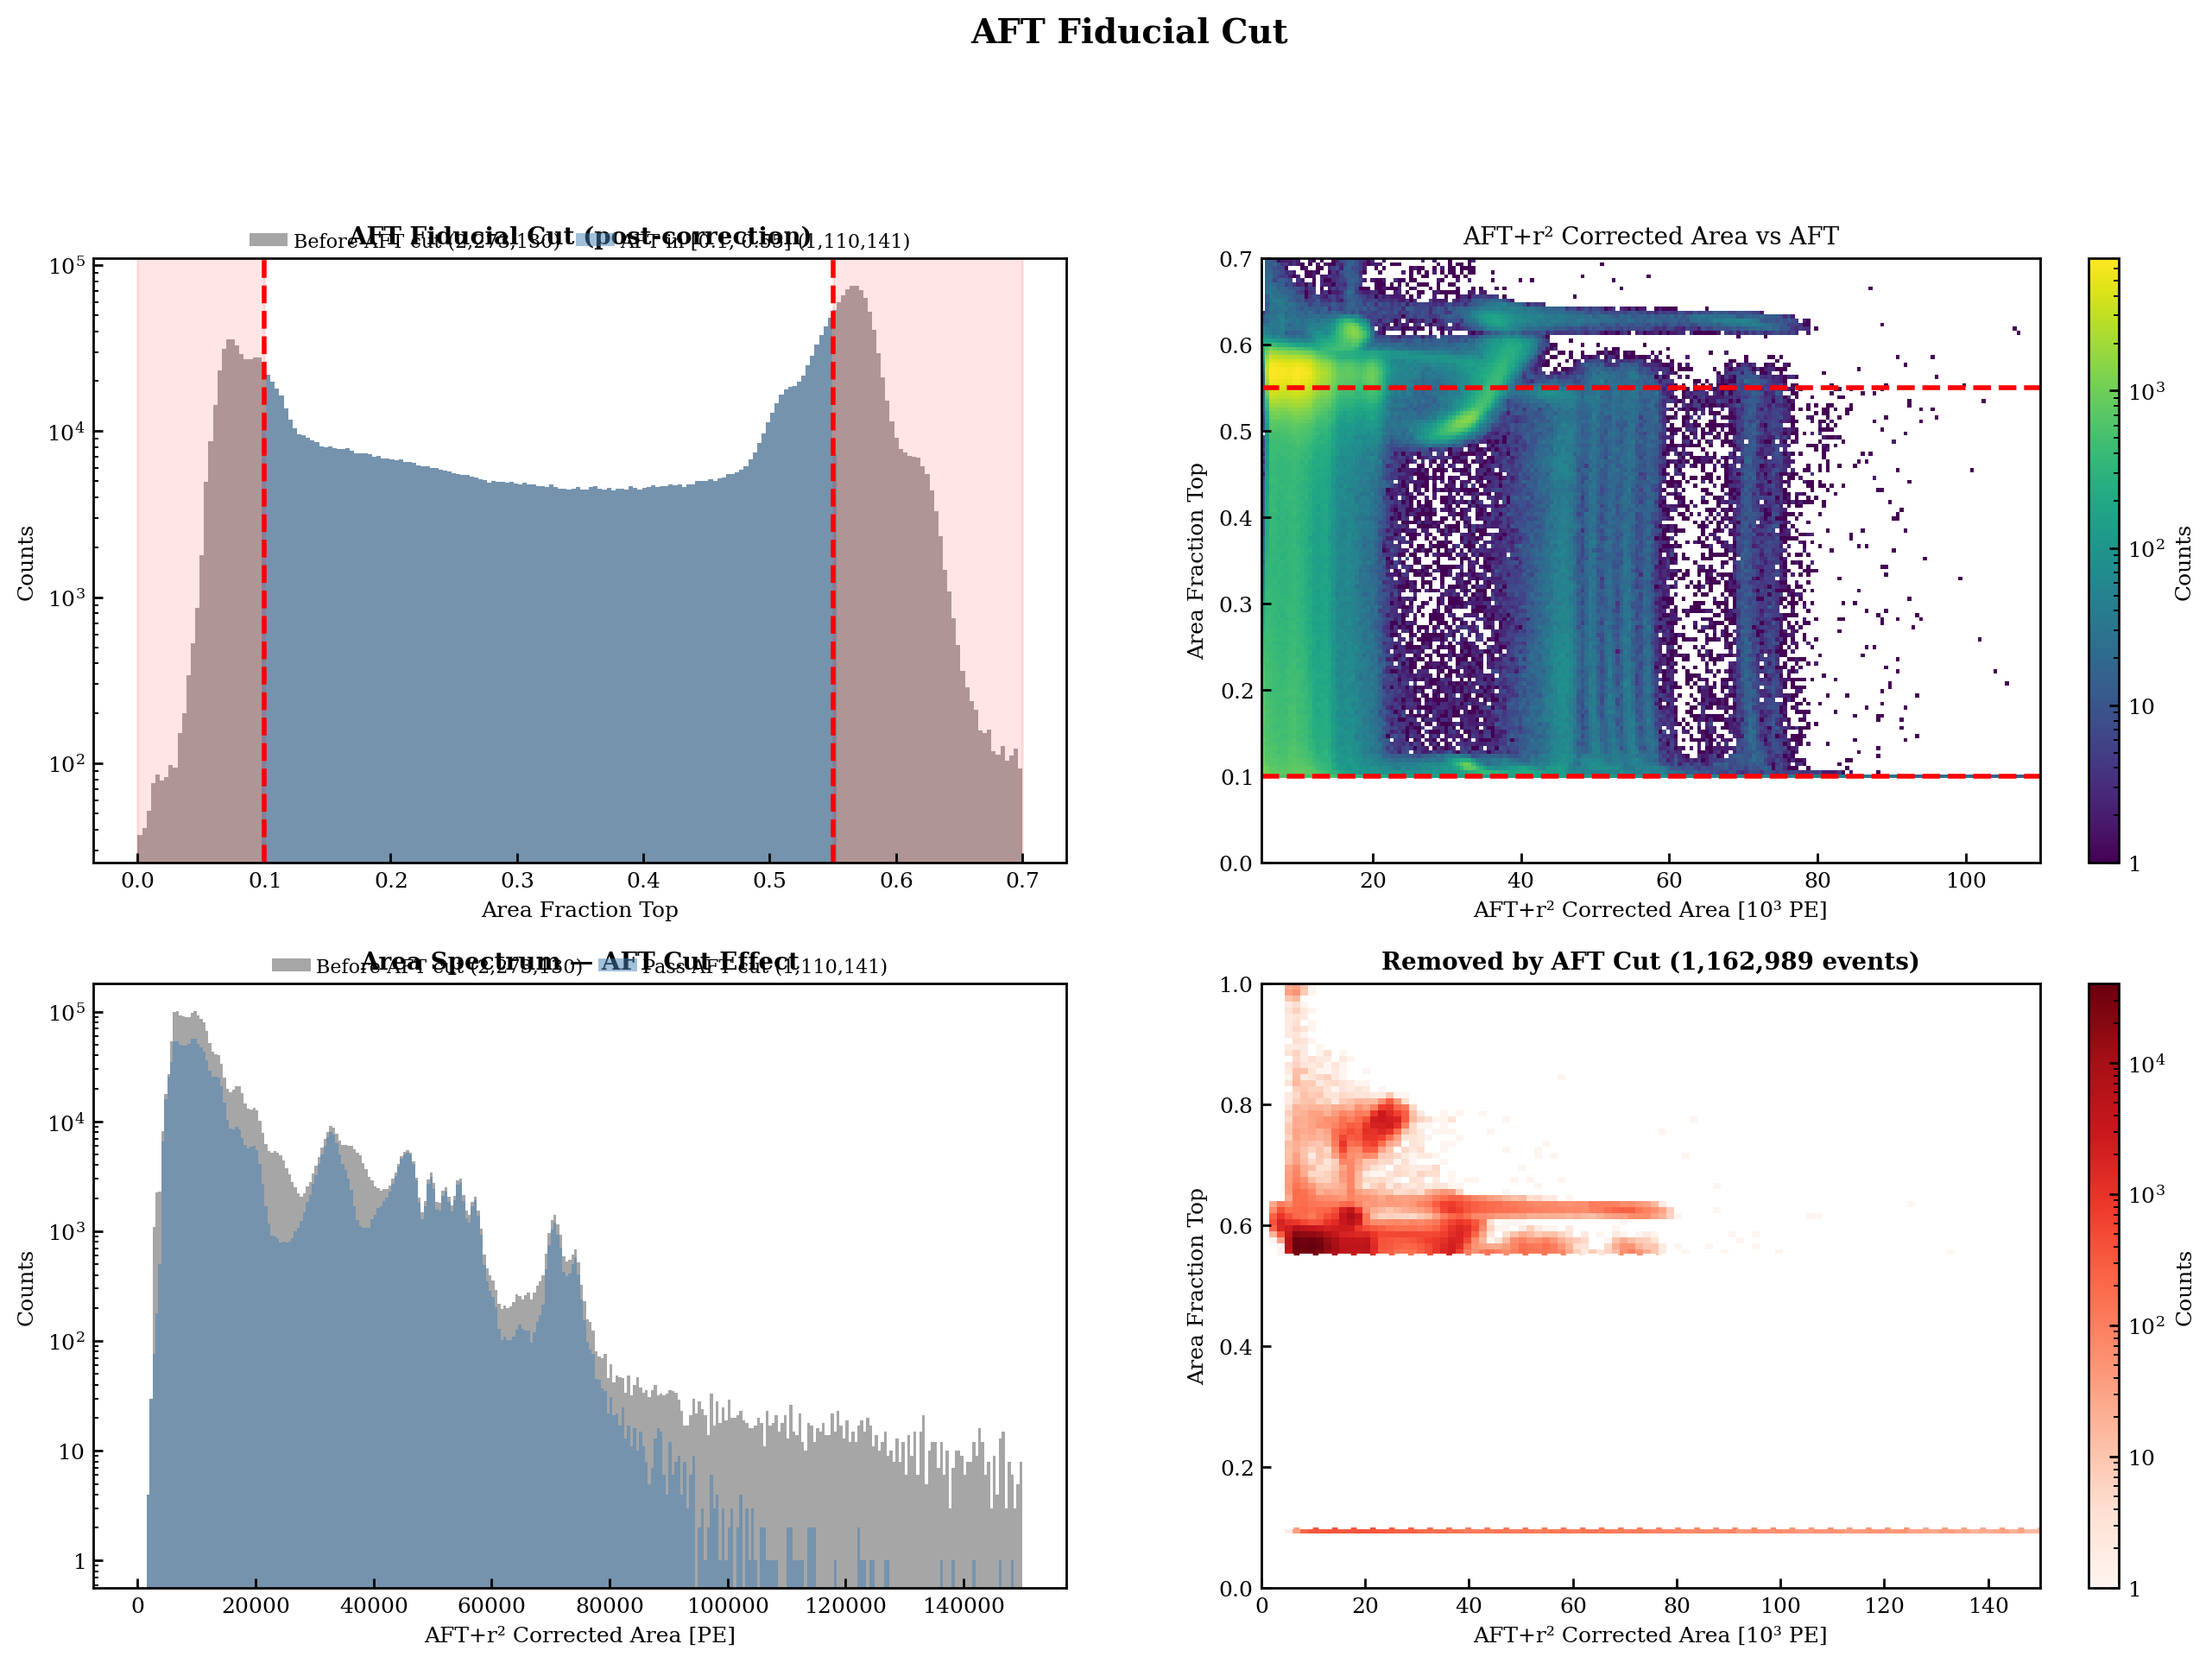

Post-correction AFT cut [0.1, 0.55]:
  Before: 2,273,130
  After:  1,110,141
  Removed: 1,162,989 (51.2%)

FV cut [AFT 0.15-0.45, r2_aft_corrected < 38]:
  Before: 1,110,141
  After:  49,268
  Removed: 1,060,873 (95.6%)


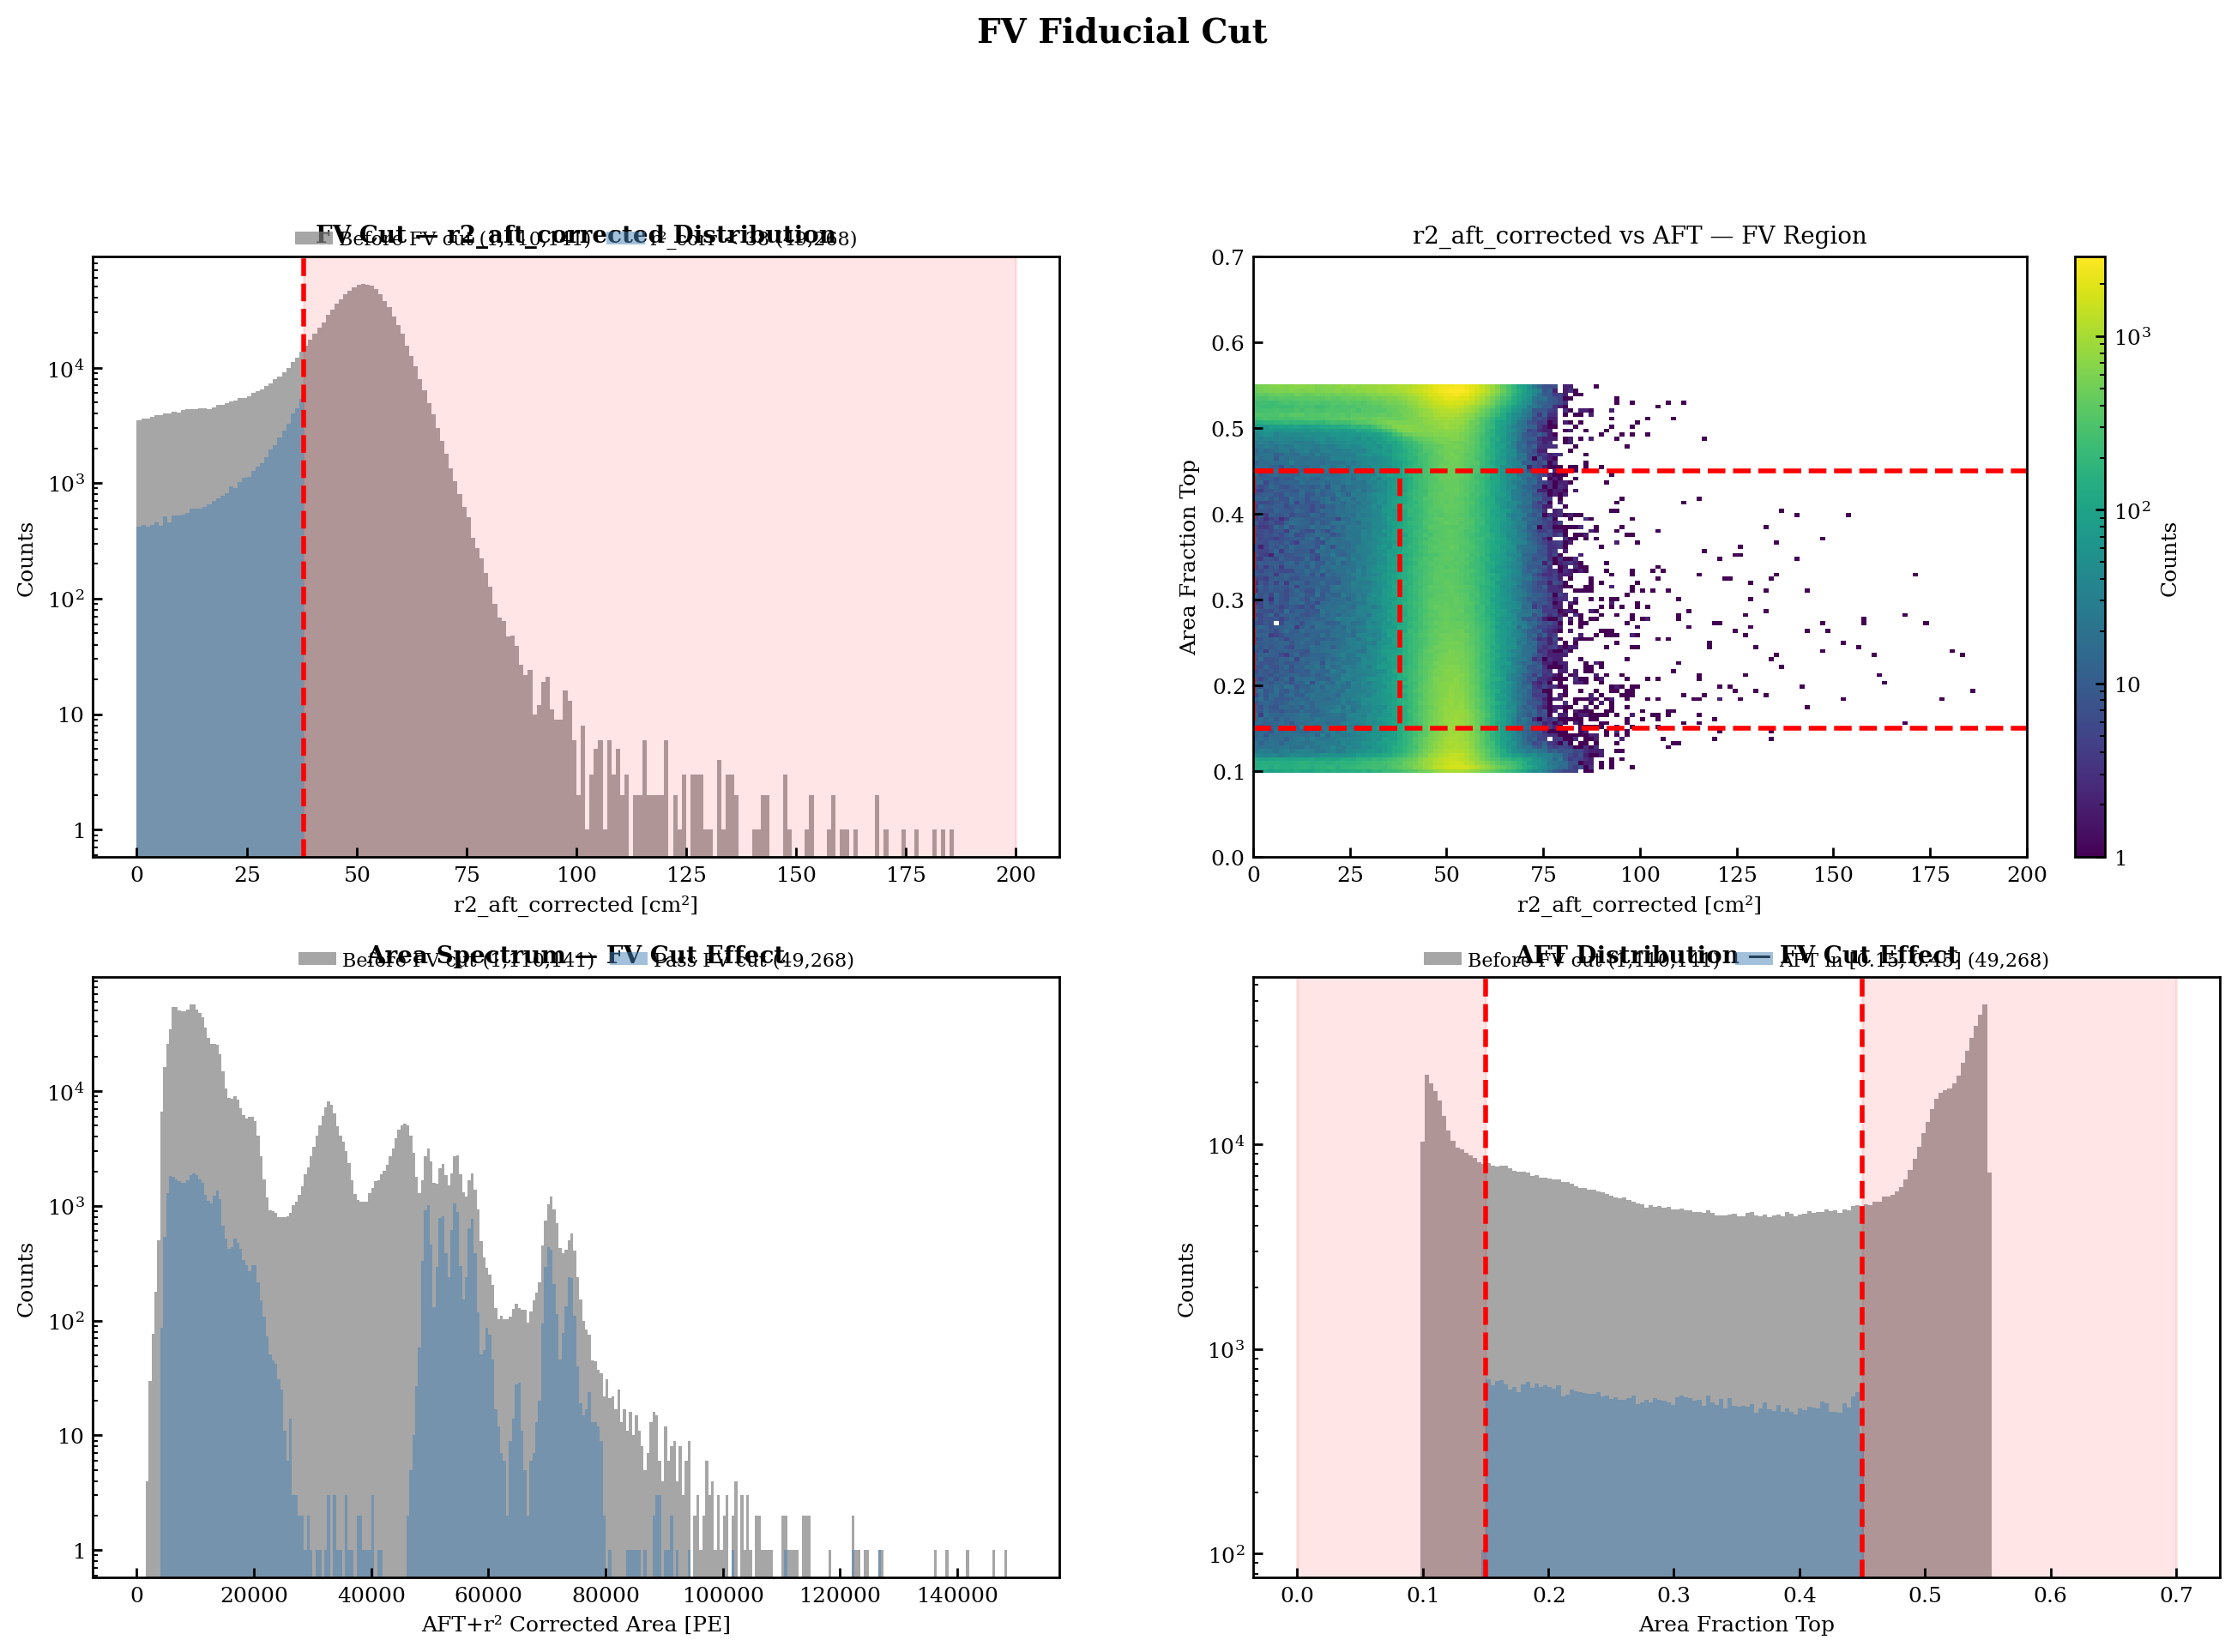


d_cor_aft has 49,268 events — ready for rate calculation.


In [147]:
# ═══════════════════════════════════════════════════════════════
# AFT FIDUCIAL CUT — applied after corrections
# ═══════════════════════════════════════════════════════════════

AFT_MIN = 0.1
AFT_MAX = 0.55

m_aft = (d_cor['area_fraction_top'] > AFT_MIN) & (d_cor['area_fraction_top'] < AFT_MAX)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Top-left: AFT 1D
ax = axes[0, 0]
ax.hist(d_cor['area_fraction_top'], bins=200, range=[0, 0.7],
        color='gray', alpha=0.7, label=f'Before AFT cut ({len(d_cor):,})')
ax.hist(d_cor.loc[m_aft, 'area_fraction_top'], bins=200, range=[0, 0.7],
        color='steelblue', alpha=0.5,
        label=f'AFT in [{AFT_MIN}, {AFT_MAX}] ({m_aft.sum():,})')
ax.axvline(x=AFT_MIN, color='red', ls='--', lw=2)
ax.axvline(x=AFT_MAX, color='red', ls='--', lw=2)
ax.axvspan(0, AFT_MIN, alpha=0.1, color='red')
ax.axvspan(AFT_MAX, 0.7, alpha=0.1, color='red')
ax.set_xlabel('Area Fraction Top')
ax.set_ylabel('Counts')
ax.set_yscale('log')
ax.set_title('AFT Fiducial Cut (post-correction)', fontweight='bold')
ax.legend(fontsize=8)

# Top-right: AFT+r² Corrected Area vs AFT
ax = axes[0, 1]
h = ax.hist2d(d_cor['area_2_corrected']/1e3, d_cor['area_fraction_top'],
              bins=[200, 150], range=[[5, 110], [0, 0.7]],
              cmin=1, norm=matplotlib.colors.LogNorm(), cmap='viridis')
ax.axhline(y=AFT_MIN, color='red', ls='--', lw=2)
ax.axhline(y=AFT_MAX, color='red', ls='--', lw=2)
ax.set_xlabel('AFT+r² Corrected Area [10³ PE]')
ax.set_ylabel('Area Fraction Top')
ax.set_title('AFT+r² Corrected Area vs AFT')
plt.colorbar(h[3], ax=ax, label='Counts')

# Bottom-left: Area 1D before/after
ax = axes[1, 0]
ax.hist(d_cor['area_2_corrected'], bins=300, range=[0, 150e3],
        color='gray', alpha=0.7, label=f'Before AFT cut ({len(d_cor):,})')
ax.hist(d_cor.loc[m_aft, 'area_2_corrected'], bins=300, range=[0, 150e3],
        color='steelblue', alpha=0.5,
        label=f'Pass AFT cut ({m_aft.sum():,})')
ax.set_xlabel('AFT+r² Corrected Area [PE]')
ax.set_ylabel('Counts')
ax.set_yscale('log')
ax.set_title('Area Spectrum — AFT Cut Effect', fontweight='bold')
ax.legend(fontsize=8)

# Bottom-right: Removed events
ax = axes[1, 1]
removed = ~m_aft
h = ax.hist2d(d_cor.loc[removed, 'area_2_corrected']/1e3,
              d_cor.loc[removed, 'area_fraction_top'],
              bins=[100, 100], range=[[0, 150], [0, 1.0]],
              cmin=1, norm=matplotlib.colors.LogNorm(), cmap='Reds')
ax.axhline(y=AFT_MIN, color='white', ls='--', lw=1.5)
ax.axhline(y=AFT_MAX, color='white', ls='--', lw=1.5)
ax.set_xlabel('AFT+r² Corrected Area [10³ PE]')
ax.set_ylabel('Area Fraction Top')
ax.set_title(f'Removed by AFT Cut ({removed.sum():,} events)', fontweight='bold')
plt.colorbar(h[3], ax=ax, label='Counts')

fig.suptitle('AFT Fiducial Cut', fontsize=14, fontweight='bold', y=1.02)
safe_tight(fig)
plt.show()

# ── Apply AFT cut ──
d_cor_aft = d_cor[m_aft].copy().reset_index(drop=True)

print(f'Post-correction AFT cut [{AFT_MIN}, {AFT_MAX}]:')
print(f'  Before: {len(d_cor):,}')
print(f'  After:  {len(d_cor_aft):,}')
print(f'  Removed: {(~m_aft).sum():,} ({100*(~m_aft).sum()/len(d_cor):.1f}%)')

# ═══════════════════════════════════════════════════════════════
# FV CUT — in corrected r² vs AFT space (r2_aft_corrected)
# ═══════════════════════════════════════════════════════════════

AFT_FV_MIN, AFT_FV_MAX = 0.15, 0.45
R2_FV_MAX = 38

m_fv = (
    (d_cor_aft['area_fraction_top'] >= AFT_FV_MIN) &
    (d_cor_aft['area_fraction_top'] <= AFT_FV_MAX) &
    (d_cor_aft['r2_aft_corrected'] >= 0) &
    (d_cor_aft['r2_aft_corrected'] <= R2_FV_MAX)
)

print(f'\nFV cut [AFT {AFT_FV_MIN}-{AFT_FV_MAX}, r2_aft_corrected < {R2_FV_MAX}]:')
print(f'  Before: {len(d_cor_aft):,}')
print(f'  After:  {m_fv.sum():,}')
print(f'  Removed: {(~m_fv).sum():,} ({100*(~m_fv).sum()/len(d_cor_aft):.1f}%)')

# ── FV Cut diagnostic plots ──
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Top-left: r2_aft_corrected 1D before/after
ax = axes[0, 0]
ax.hist(d_cor_aft['r2_aft_corrected'], bins=200, range=[0, 200],
        color='gray', alpha=0.7, label=f'Before FV cut ({len(d_cor_aft):,})')
ax.hist(d_cor_aft.loc[m_fv, 'r2_aft_corrected'], bins=200, range=[0, 200],
        color='steelblue', alpha=0.5,
        label=f'r²_corr < {R2_FV_MAX} ({m_fv.sum():,})')
ax.axvline(x=R2_FV_MAX, color='red', ls='--', lw=2)
ax.axvspan(R2_FV_MAX, 200, alpha=0.1, color='red')
ax.set_xlabel('r2_aft_corrected [cm²]')
ax.set_ylabel('Counts')
ax.set_yscale('log')
ax.set_title('FV Cut — r2_aft_corrected Distribution', fontweight='bold')
ax.legend(fontsize=8)

# Top-right: r2_aft_corrected vs AFT with FV box
ax = axes[0, 1]
h = ax.hist2d(d_cor_aft['r2_aft_corrected'], d_cor_aft['area_fraction_top'],
              bins=[150, 150], range=[[0, 200], [0, 0.7]],
              cmin=1, norm=matplotlib.colors.LogNorm(), cmap='viridis')
from matplotlib.patches import Rectangle
rect = Rectangle((0, AFT_FV_MIN), R2_FV_MAX, AFT_FV_MAX - AFT_FV_MIN,
                 linewidth=2, edgecolor='red', facecolor='none', ls='--')
ax.add_patch(rect)
ax.axhline(y=AFT_FV_MIN, color='red', ls='--', lw=2)
ax.axhline(y=AFT_FV_MAX, color='red', ls='--', lw=2)
ax.set_xlabel('r2_aft_corrected [cm²]')
ax.set_ylabel('Area Fraction Top')
ax.set_title('r2_aft_corrected vs AFT — FV Region')
plt.colorbar(h[3], ax=ax, label='Counts')

# Bottom-left: AFT+r² Corrected Area 1D before/after
ax = axes[1, 0]
ax.hist(d_cor_aft['area_2_corrected'], bins=300, range=[0, 150e3],
        color='gray', alpha=0.7, label=f'Before FV cut ({len(d_cor_aft):,})')
ax.hist(d_cor_aft.loc[m_fv, 'area_2_corrected'], bins=300, range=[0, 150e3],
        color='steelblue', alpha=0.5,
        label=f'Pass FV cut ({m_fv.sum():,})')
ax.set_xlabel('AFT+r² Corrected Area [PE]')
ax.set_ylabel('Counts')
ax.set_yscale('log')
ax.set_title('Area Spectrum — FV Cut Effect', fontweight='bold')
ax.legend(fontsize=8)

# Bottom-right: AFT 1D before/after
ax = axes[1, 1]
ax.hist(d_cor_aft['area_fraction_top'], bins=200, range=[0, 0.7],
        color='gray', alpha=0.7, label=f'Before FV cut ({len(d_cor_aft):,})')
ax.hist(d_cor_aft.loc[m_fv, 'area_fraction_top'], bins=200, range=[0, 0.7],
        color='steelblue', alpha=0.5,
        label=f'AFT in [{AFT_FV_MIN}, {AFT_FV_MAX}] ({m_fv.sum():,})')
ax.axvline(x=AFT_FV_MIN, color='red', ls='--', lw=2)
ax.axvline(x=AFT_FV_MAX, color='red', ls='--', lw=2)
ax.axvspan(0, AFT_FV_MIN, alpha=0.1, color='red')
ax.axvspan(AFT_FV_MAX, 0.7, alpha=0.1, color='red')
ax.set_xlabel('Area Fraction Top')
ax.set_ylabel('Counts')
ax.set_yscale('log')
ax.set_title('AFT Distribution — FV Cut Effect', fontweight='bold')
ax.legend(fontsize=8)

fig.suptitle('FV Fiducial Cut', fontsize=14, fontweight='bold', y=1.02)
safe_tight(fig)
plt.show()

# ── Apply FV cut ──
d_cor_aft = d_cor_aft[m_fv].copy().reset_index(drop=True)

print(f'\nd_cor_aft has {len(d_cor_aft):,} events — ready for rate calculation.')

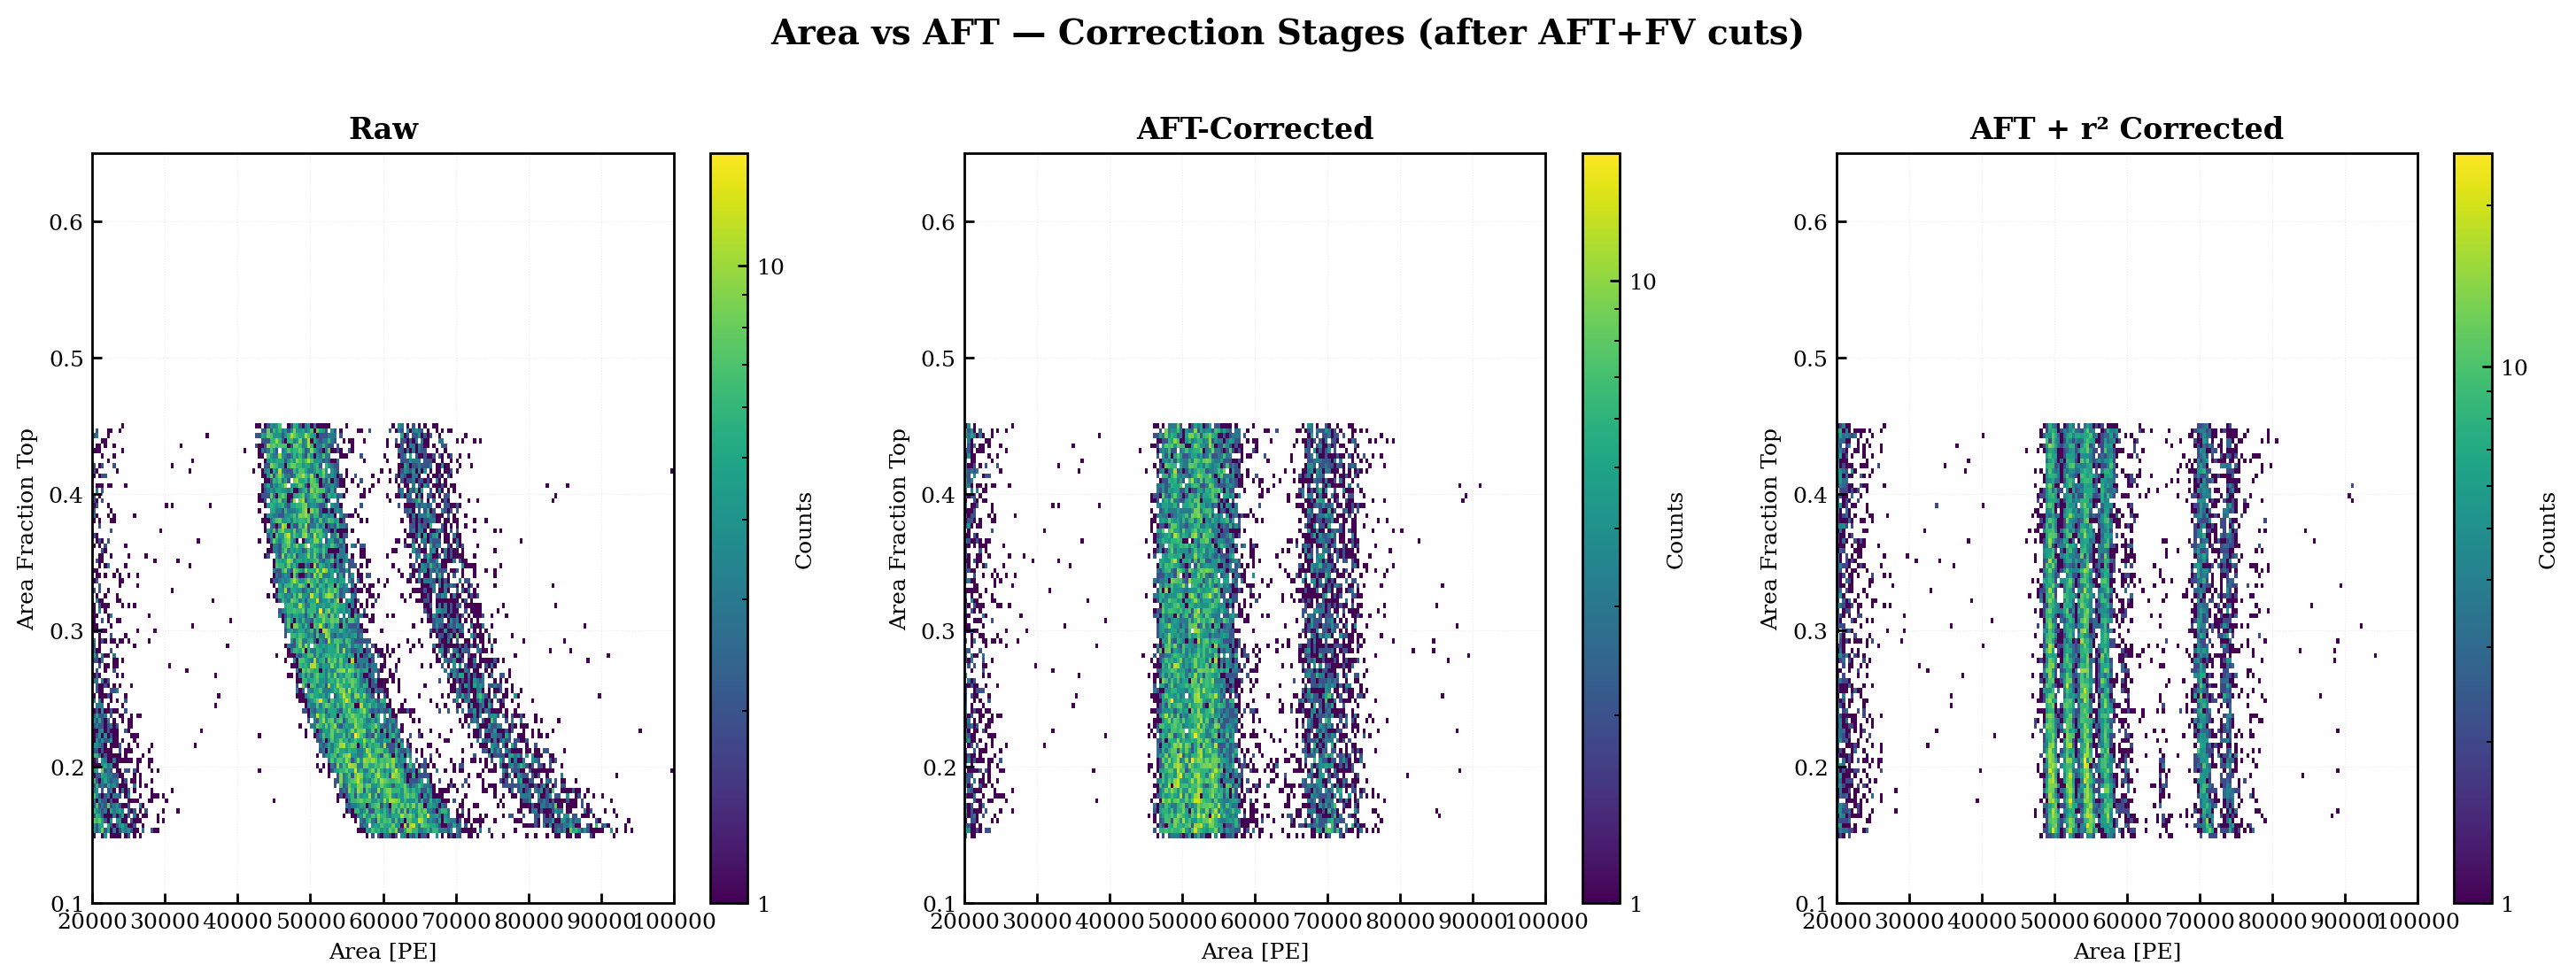

In [148]:
# ═══════════════════════════════════════════════════════════════
# BEFORE/AFTER COMPARISON — all correction stages
# ═══════════════════════════════════════════════════════════════

stages = [
    ('Raw',                    'area'),
    ('AFT-Corrected',          'area_aft_corrected'),
    ('AFT + r² Corrected',     'area_2_corrected'),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

for ax, (label, col) in zip(axes, stages):
    if col in d_cor_aft.columns:
        h = ax.hist2d(d_cor_aft[col], d_cor_aft['area_fraction_top'],
                      bins=[200, 150],
                      range=[[20e3, 100e3], [0.1, 0.65]],
                      cmin=1, norm=matplotlib.colors.LogNorm())
        plt.colorbar(h[3], ax=ax, label='Counts')
        ax.set_xlabel('Area [PE]')
        ax.set_ylabel('Area Fraction Top')
        ax.set_title(label, fontweight='bold', fontsize=12)
        ax.grid(True, alpha=0.2)

fig.suptitle('Area vs AFT — Correction Stages (after AFT+FV cuts)', fontsize=14, fontweight='bold', y=1.02)
safe_tight(fig)
plt.show()

---
## Rate Calculation

Use all events after applying all fiducial cuts and corrections.

Events for rate analysis (after all cuts + corrections): 49,268


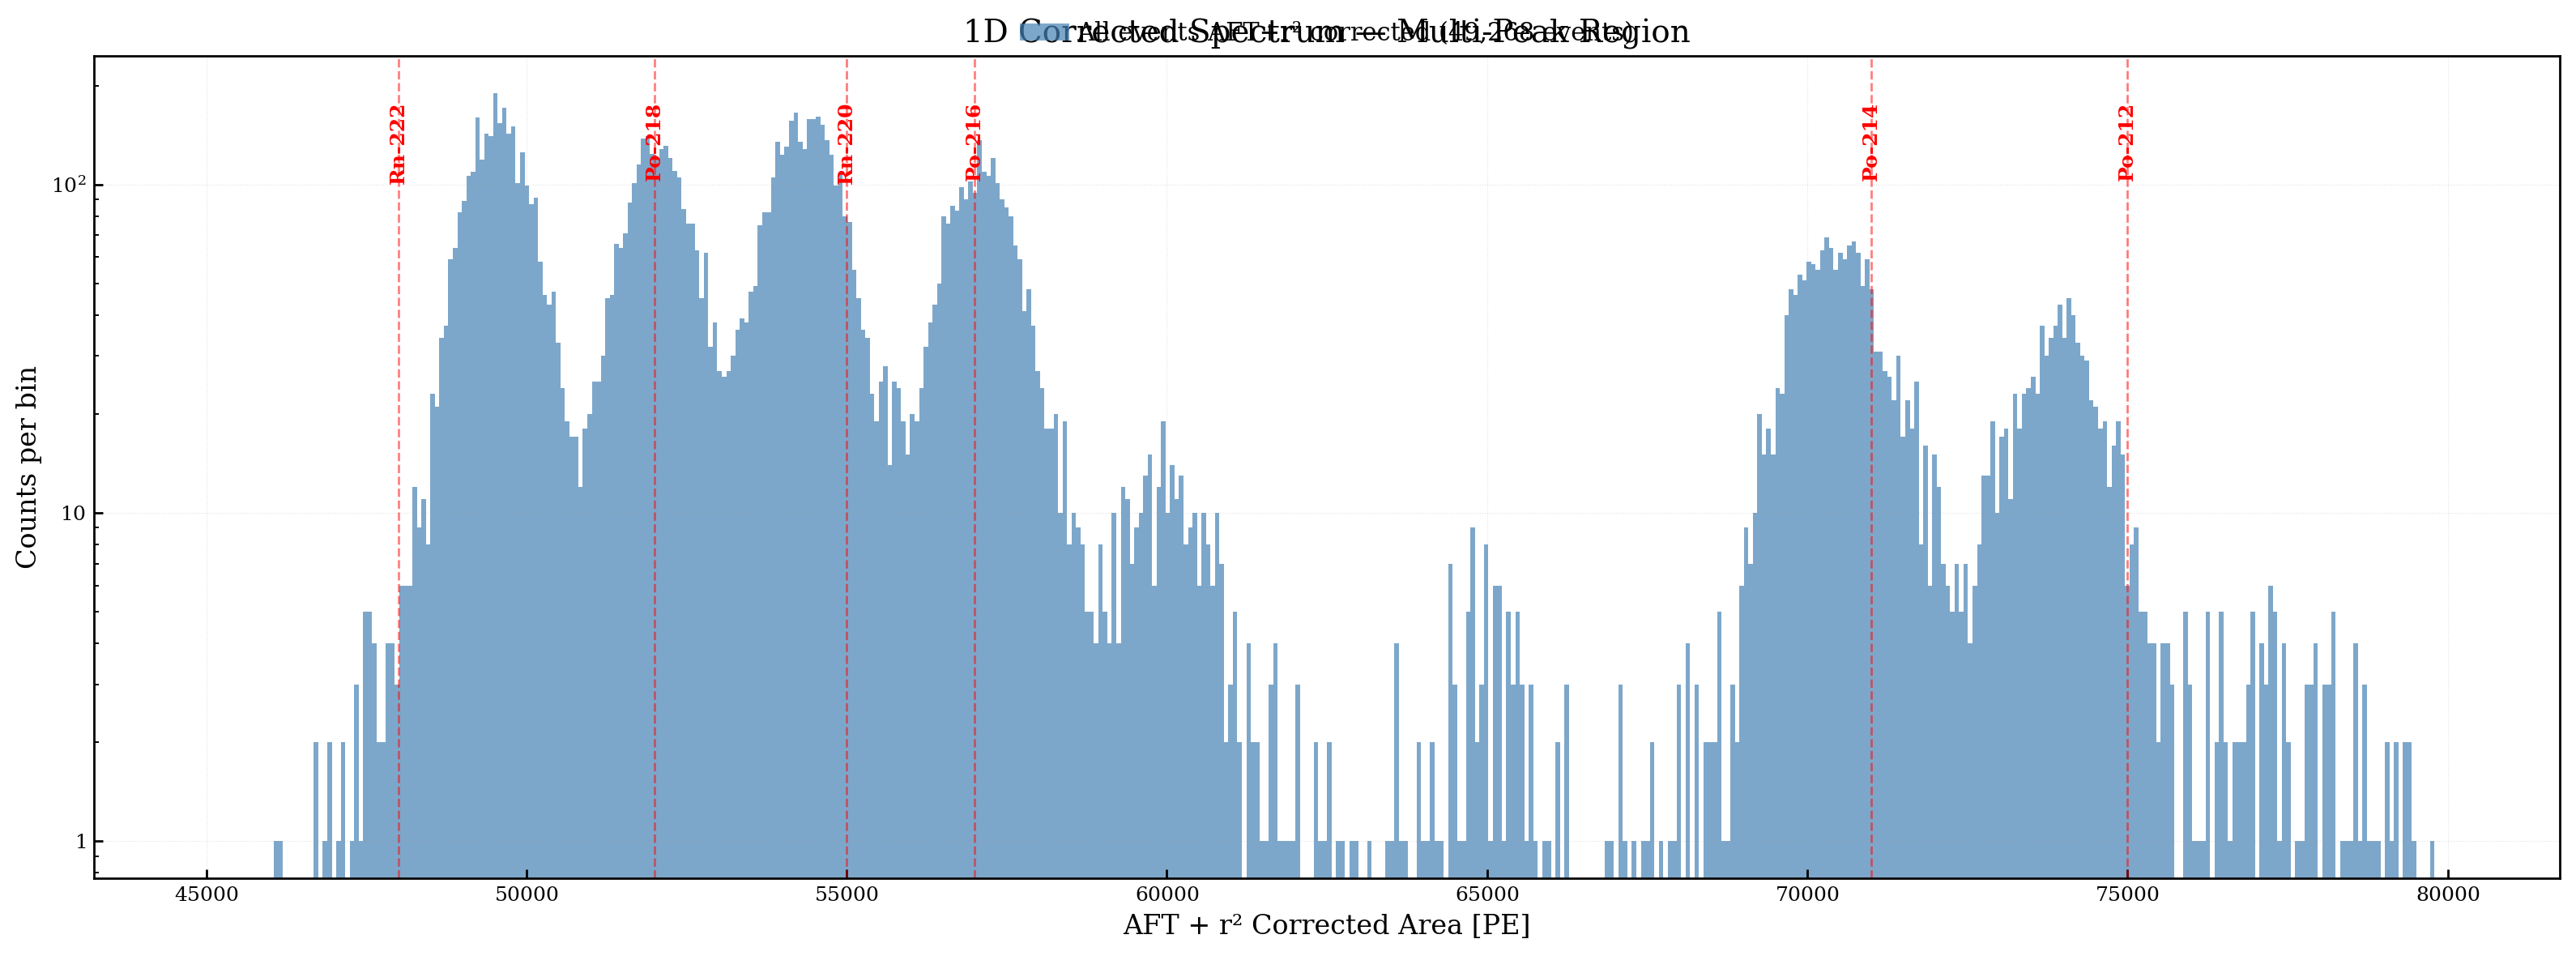


Spectrum range: 45000 – 80000 PE
Bin width: 70.0 PE
Max bin count: 189
Total counts in histogram: 13,695

Detected peak positions (for reference):
  49515 PE (height: 189)
  54205 PE (height: 165)
  51895 PE (height: 140)
  57075 PE (height: 136)
  70305 PE (height: 69)
  74085 PE (height: 45)
  52945 PE (height: 38)
  71425 PE (height: 30)
  55605 PE (height: 28)
  58265 PE (height: 20)

Initial guesses for 6-Gaussian fit:
  Rn-222      μ₀ = 48,000 PE
  Po-218      μ₀ = 52,000 PE
  Rn-220      μ₀ = 55,000 PE
  Po-216      μ₀ = 57,000 PE
  Po-214      μ₀ = 71,000 PE
  Po-212      μ₀ = 75,000 PE


In [149]:
# ═══════════════════════════════════════════════════════════════
# 1D CORRECTED SPECTRUM — wide range for multi-peak fit
# ═══════════════════════════════════════════════════════════════
# Use ALL events after cuts and corrections.

rn_events = d_cor_aft.copy()
print(f'Events for rate analysis (after all cuts + corrections): {len(rn_events):,}')

# ── Rough peak guesses for multi-Gaussian fit ──
#   Rn-222 ~48k, Po-218 ~52k, Rn-220 ~55k, Po-216 ~57k,
#   Po-214 ~71k, Po-212 ~75k
GUESS_MU = [48000, 52000, 55000, 57000, 71000, 75000]
GUESS_SIGMA = 800
PEAK_NAMES = ['Rn-222', 'Po-218', 'Rn-220', 'Po-216', 'Po-214', 'Po-212']
N_PEAKS = len(GUESS_MU)

# ── Histogram ──
counts_rn, edges_rn = np.histogram(
    rn_events['area_2_corrected'],
    bins=500, range=[45e3, 80e3]
)
bin_centers_rn = 0.5 * (edges_rn[:-1] + edges_rn[1:])
bin_width_rn = edges_rn[1] - edges_rn[0]

fig, ax = plt.subplots(figsize=(16, 6))

ax.hist(
    rn_events['area_2_corrected'],
    bins=500, range=[45e3, 80e3],
    color='steelblue', alpha=0.7,
    label=f'All events AFT+r² corrected ({len(rn_events):,} events)'
)

# Mark guess positions
for mu, name in zip(GUESS_MU, PEAK_NAMES):
    ax.axvline(x=mu, color='red', ls='--', lw=1, alpha=0.5)
    ax.annotate(name, xy=(mu, ax.get_ylim()[1]*0.9), fontsize=9,
                color='red', ha='center', fontweight='bold',
                rotation=90, va='top')

ax.set_xlabel('AFT + r² Corrected Area [PE]', fontsize=12)
ax.set_ylabel('Counts per bin', fontsize=12)
ax.set_yscale('log')
ax.set_title('1D Corrected Spectrum — Multi-Peak Region', fontsize=14)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
safe_tight(fig)
plt.show()

# Find peak positions for initial guesses
peaks_idx, peaks_props = find_peaks(counts_rn, height=counts_rn.max()*0.02, distance=15)
peak_positions = bin_centers_rn[peaks_idx]
peak_heights = counts_rn[peaks_idx]

print(f'\nSpectrum range: {edges_rn[0]:.0f} – {edges_rn[-1]:.0f} PE')
print(f'Bin width: {bin_width_rn:.1f} PE')
print(f'Max bin count: {counts_rn.max():.0f}')
print(f'Total counts in histogram: {counts_rn.sum():,.0f}')
print(f'\nDetected peak positions (for reference):')
for pos, height in sorted(zip(peak_positions, peak_heights), key=lambda x: x[1], reverse=True)[:10]:
    print(f'  {pos:.0f} PE (height: {height:.0f})')

print(f'\nInitial guesses for {N_PEAKS}-Gaussian fit:')
for name, mu in zip(PEAK_NAMES, GUESS_MU):
    print(f'  {name:10s}  μ₀ = {mu:,} PE')

Fitting 6 Gaussians + background (19 parameters)...
  y_fit range: [0, 189]

  MULTI-GAUSSIAN FIT RESULTS
Peak             μ [PE]     σ [PE]    Amplitude      σ/μ
-------------------------------------------------------------------------------------
Rn-222         49556 ±    12     500 ±   10       154 ±      5   1.01%
Po-218         52038 ±    15     506 ±   14       128 ±      4   0.97%
Rn-220         54356 ±    14     549 ±   12       155 ±      4   1.01%
Po-216         57103 ±    16     576 ±   14       105 ±      4   1.01%
Po-214         70472 ±    22     652 ±   17        64 ±      3   0.92%
Po-212         73908 ±    32     667 ±   28        33 ±      2   0.90%
bg                     —           —       1.0 ±    0.1


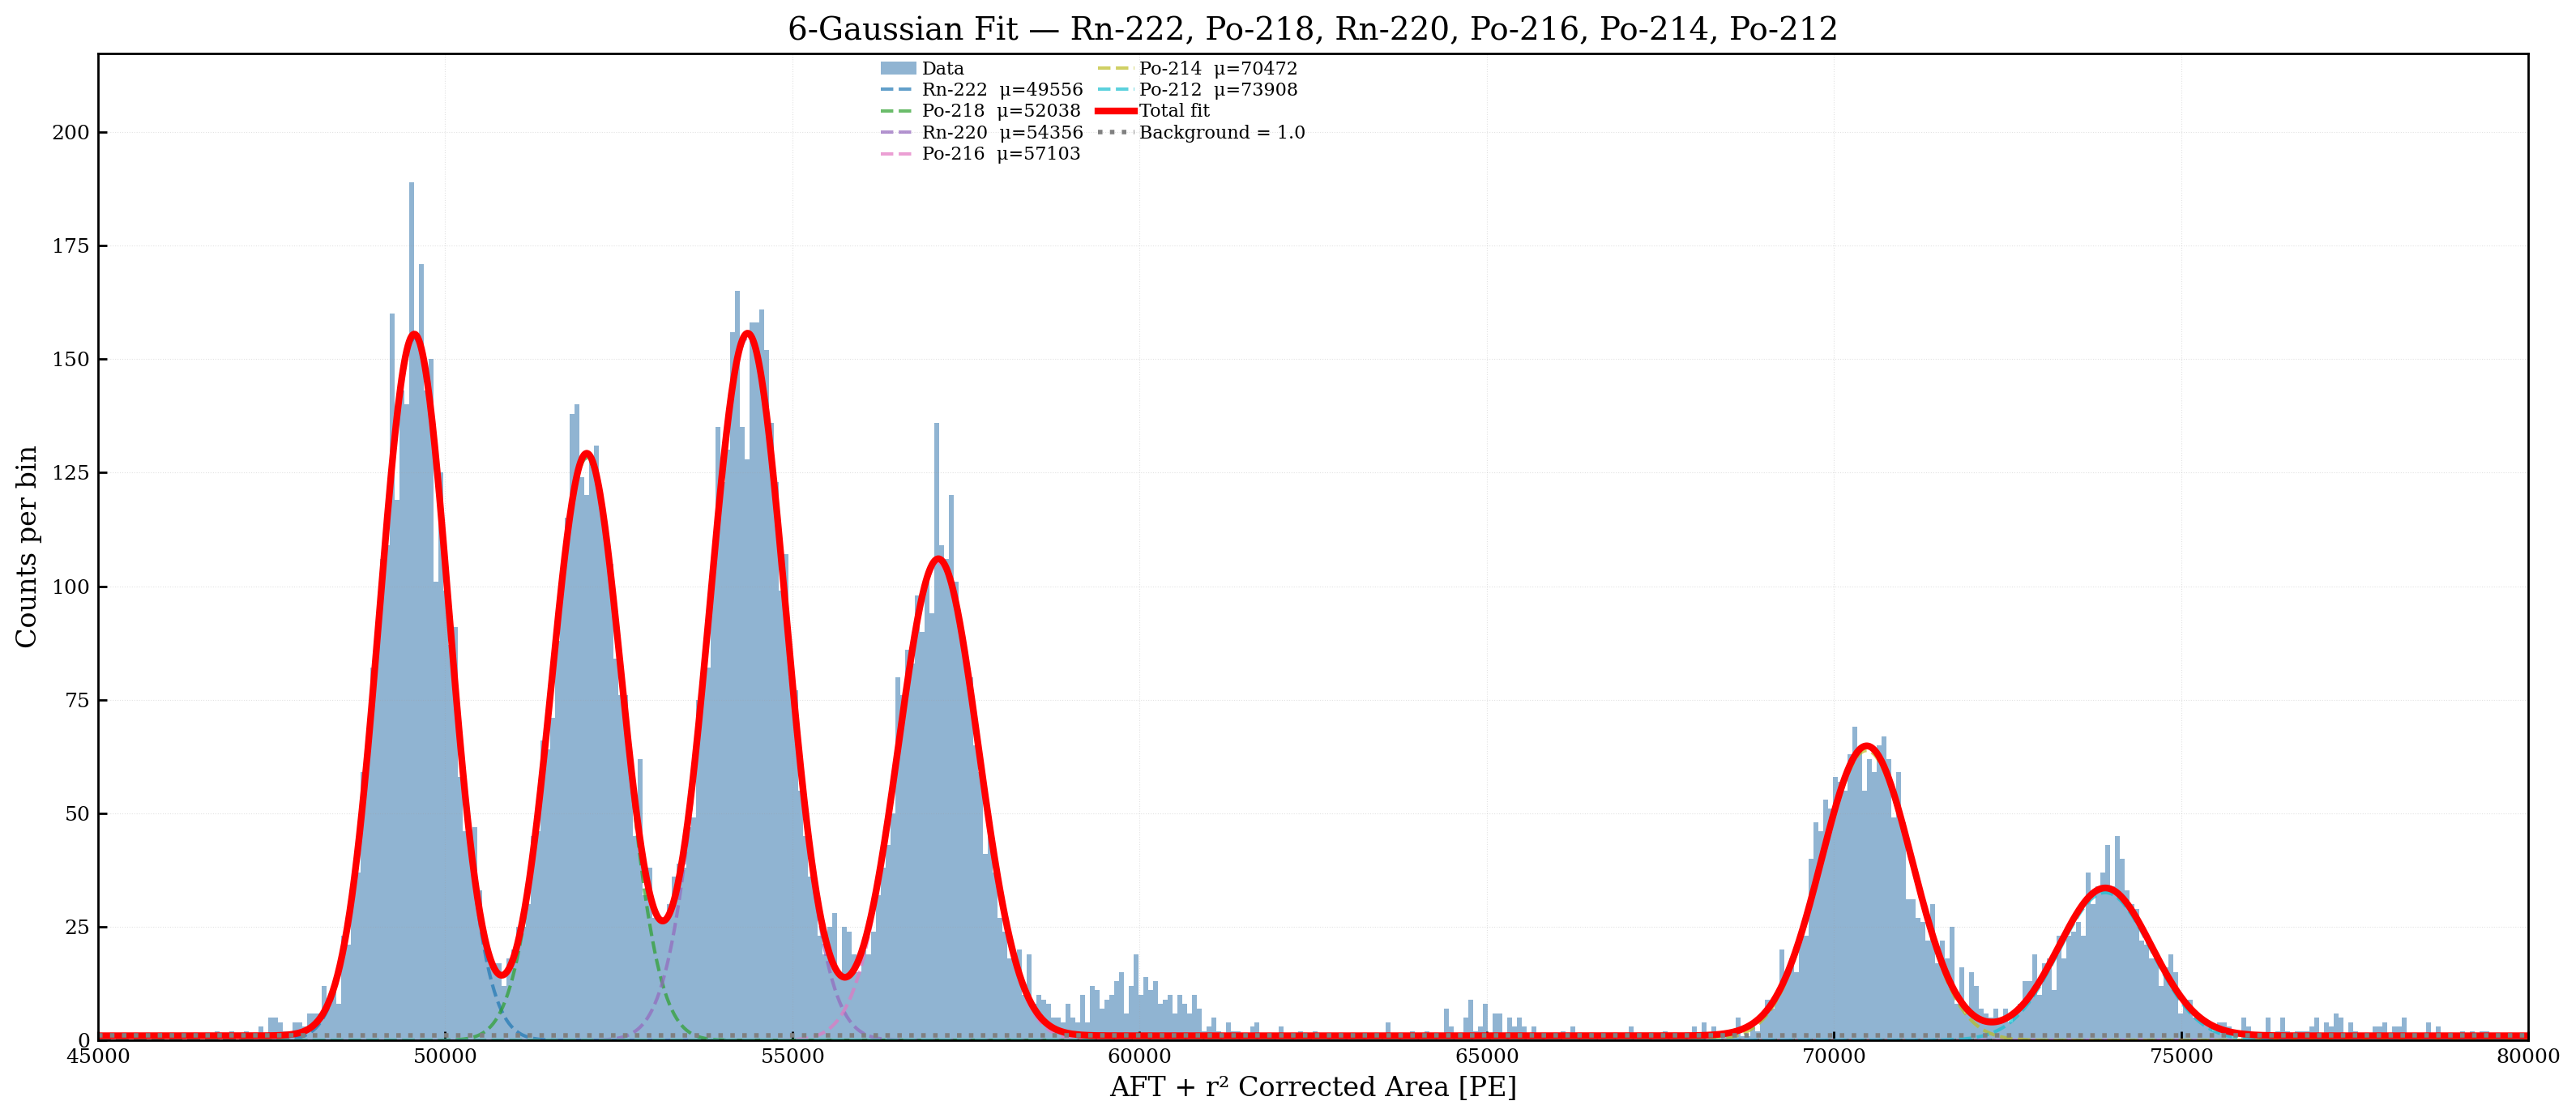


  RATE CALCULATION  (livetime = 47.01 days = 1128.2 h)
Isotope                 Window [PE]   Events      Rate [mHz]      Rate [μHz]
--------------------------------------------------------------------------------
Rn-222      [ 48057,  51054]     2,914      0.7175 ±   0.0133      717.49 ±    13.29
Po-218      [ 50522,  53555]     2,679      0.6596 ±   0.0127      659.63 ±    12.74
Rn-220      [ 52708,  56004]     3,424      0.8431 ±   0.0144      843.07 ±    14.41
Po-216      [ 55374,  58832]     2,382      0.5865 ±   0.0120      586.50 ±    12.02
Po-214      [ 68517,  72428]     1,625      0.4001 ±   0.0099      400.11 ±     9.93
Po-212      [ 71908,  75909]       916      0.2255 ±   0.0075      225.54 ±     7.45


In [150]:
# ═══════════════════════════════════════════════════════════════
# MULTI-GAUSSIAN FIT + RATE CALCULATION
# ═══════════════════════════════════════════════════════════════
# 6 peaks: Rn-222, Po-218, Rn-220, Po-216, Po-214, Po-212
# + constant background.  Fit is performed on binned counts.

def multi_gaussian(x, *params):
    """Sum of N_PEAKS Gaussians + constant background.
    params = [amp0, mu0, sig0, amp1, mu1, sig1, ..., bg]"""
    bg = params[-1]
    result = bg * np.ones_like(x)
    for i in range(N_PEAKS):
        amp = params[3*i]
        mu  = params[3*i + 1]
        sig = params[3*i + 2]
        result += amp * np.exp(-0.5 * ((x - mu) / sig)**2)
    return result

# ── Fit on binned counts ──
mask_fit = (bin_centers_rn >= 45e3) & (bin_centers_rn <= 80e3)
x_fit = bin_centers_rn[mask_fit]
y_fit = counts_rn[mask_fit]
y_err = np.sqrt(np.maximum(y_fit, 1))

# Build initial guesses from histogram
p0 = []
bounds_lower = []
bounds_upper = []

for i, mu0 in enumerate(GUESS_MU):
    idx = np.argmin(np.abs(x_fit - mu0))
    amp0 = max(y_fit[idx] * 0.5, 10)
    sig0 = GUESS_SIGMA
    p0.extend([amp0, mu0, sig0])
    bounds_lower.extend([0, mu0 - 2000, 200])
    bounds_upper.extend([np.inf, mu0 + 2000, 3000])

# Background: median of low-count bins
p0.append(1.0)
bounds_lower.append(0)
bounds_upper.append(np.inf)

print(f'Fitting {N_PEAKS} Gaussians + background ({len(p0)} parameters)...')
print(f'  y_fit range: [{y_fit.min():.0f}, {y_fit.max():.0f}]')

try:
    p_fit, p_cov_fit = curve_fit(
        multi_gaussian, x_fit, y_fit,
        p0=p0, sigma=y_err,
        bounds=(bounds_lower, bounds_upper),
        maxfev=50000
    )
    p_err = np.sqrt(np.diag(p_cov_fit))
    fit_ok = True
except Exception as e:
    print(f'Bounded fit failed: {e}')
    print('Trying without bounds...')
    try:
        p_fit, p_cov_fit = curve_fit(
            multi_gaussian, x_fit, y_fit,
            p0=p0, sigma=y_err,
            maxfev=50000
        )
        p_err = np.sqrt(np.diag(p_cov_fit))
        fit_ok = True
    except Exception as e2:
        print(f'Fit failed again: {e2}')
        p_fit = None
        fit_ok = False

if fit_ok:
    print(f'\n{"="*85}')
    print(f'  MULTI-GAUSSIAN FIT RESULTS')
    print(f'{"="*85}')
    print(f'{"Peak":10s} {"μ [PE]":>12s} {"σ [PE]":>10s} {"Amplitude":>12s} {"σ/μ":>8s}')
    print(f'{"-"*85}')

    for i in range(N_PEAKS):
        amp = p_fit[3*i]
        mu  = p_fit[3*i + 1]
        sig = p_fit[3*i + 2]
        amp_err = p_err[3*i]
        mu_err  = p_err[3*i + 1]
        sig_err = p_err[3*i + 2]
        resolution = 100 * sig / mu
        print(f'{PEAK_NAMES[i]:10s}  {mu:8.0f} ± {mu_err:5.0f}  '
              f'{sig:6.0f} ± {sig_err:4.0f}  '
              f'{amp:8.0f} ± {amp_err:6.0f}  {resolution:5.2f}%')

    bg_fit = p_fit[-1]
    bg_err = p_err[-1]
    print(f'{"bg":10s}  {"—":>12s}  {"—":>10s}  {bg_fit:8.1f} ± {bg_err:6.1f}')
    print(f'{"="*85}')

    # ═══════════════════════════════════════════════════════════
    # PLOT: Data + total fit + individual Gaussians
    # ═══════════════════════════════════════════════════════════

    fig, ax = plt.subplots(figsize=(16, 7))

    x_fine = np.linspace(45e3, 80e3, 2000)
    y_max = y_fit.max() * 1.15

    # Data histogram
    ax.hist(rn_events['area_2_corrected'], bins=500, range=[45e3, 80e3],
            color='steelblue', alpha=0.6, label='Data')

    # Individual Gaussians
    colors = plt.cm.tab10(np.linspace(0, 1, N_PEAKS))
    for i in range(N_PEAKS):
        amp = p_fit[3*i]
        mu  = p_fit[3*i + 1]
        sig = p_fit[3*i + 2]
        g_single = amp * np.exp(-0.5 * ((x_fine - mu) / sig)**2)
        ax.plot(x_fine, g_single, '--', color=colors[i], lw=1.5, alpha=0.7,
                label=f'{PEAK_NAMES[i]}  μ={mu:.0f}')

    # Total fit (sum of all)
    y_fit_curve = multi_gaussian(x_fine, *p_fit)
    ax.plot(x_fine, y_fit_curve, 'r-', lw=3, label='Total fit')

    # Background
    ax.axhline(y=bg_fit, color='gray', ls=':', lw=2,
               label=f'Background = {bg_fit:.1f}')

    ax.set_xlabel('AFT + r² Corrected Area [PE]', fontsize=12)
    ax.set_ylabel('Counts per bin', fontsize=12)
    ax.set_xlim(45e3, 80e3)
    ax.set_ylim(0, y_max)
    ax.set_title(f'6-Gaussian Fit — Rn-222, Po-218, Rn-220, Po-216, Po-214, Po-212',
                 fontsize=14)
    ax.legend(fontsize=8, ncol=2, loc='upper right')
    ax.grid(True, alpha=0.3)
    safe_tight(fig)
    plt.show()

    # ═══════════════════════════════════════════════════════════
    # RATE CALCULATION — each peak counted within ±3σ
    # ═══════════════════════════════════════════════════════════

    livetime_ns = rn_events['time'].max() - rn_events['time'].min()
    livetime_s = livetime_ns / 1e9
    livetime_h = livetime_s / 3600
    livetime_d = livetime_h / 24

    print(f'\n{"="*80}')
    print(f'  RATE CALCULATION  (livetime = {livetime_d:.2f} days = {livetime_h:.1f} h)')
    print(f'{"="*80}')
    print(f'{"Isotope":10s} {"Window [PE]":>24s} {"Events":>8s}  {"Rate [mHz]":>14s}  {"Rate [μHz]":>14s}')
    print(f'{"-"*80}')

    for i in range(N_PEAKS):
        mu  = p_fit[3*i + 1]
        sig = p_fit[3*i + 2]
        lo = mu - 3*sig
        hi = mu + 3*sig

        n_peak = ((rn_events['area_2_corrected'] >= lo) &
                  (rn_events['area_2_corrected'] <= hi)).sum()

        rate_hz = n_peak / livetime_s
        rate_err_hz = np.sqrt(n_peak) / livetime_s

        print(f'{PEAK_NAMES[i]:10s}  [{lo:6.0f}, {hi:6.0f}]  '
              f'{n_peak:8,d}  {rate_hz*1e3:10.4f} ± {rate_err_hz*1e3:8.4f}  '
              f'{rate_hz*1e6:10.2f} ± {rate_err_hz*1e6:8.2f}')

    print(f'{"="*80}')
else:
    print('\nFit failed — cannot calculate rates.')

Time range: 2026-03-19 08:59 → 2026-05-05 09:08 UTC
Total livetime: 47.01 days
100 bins, bin width = 40614 s = 11.28 h


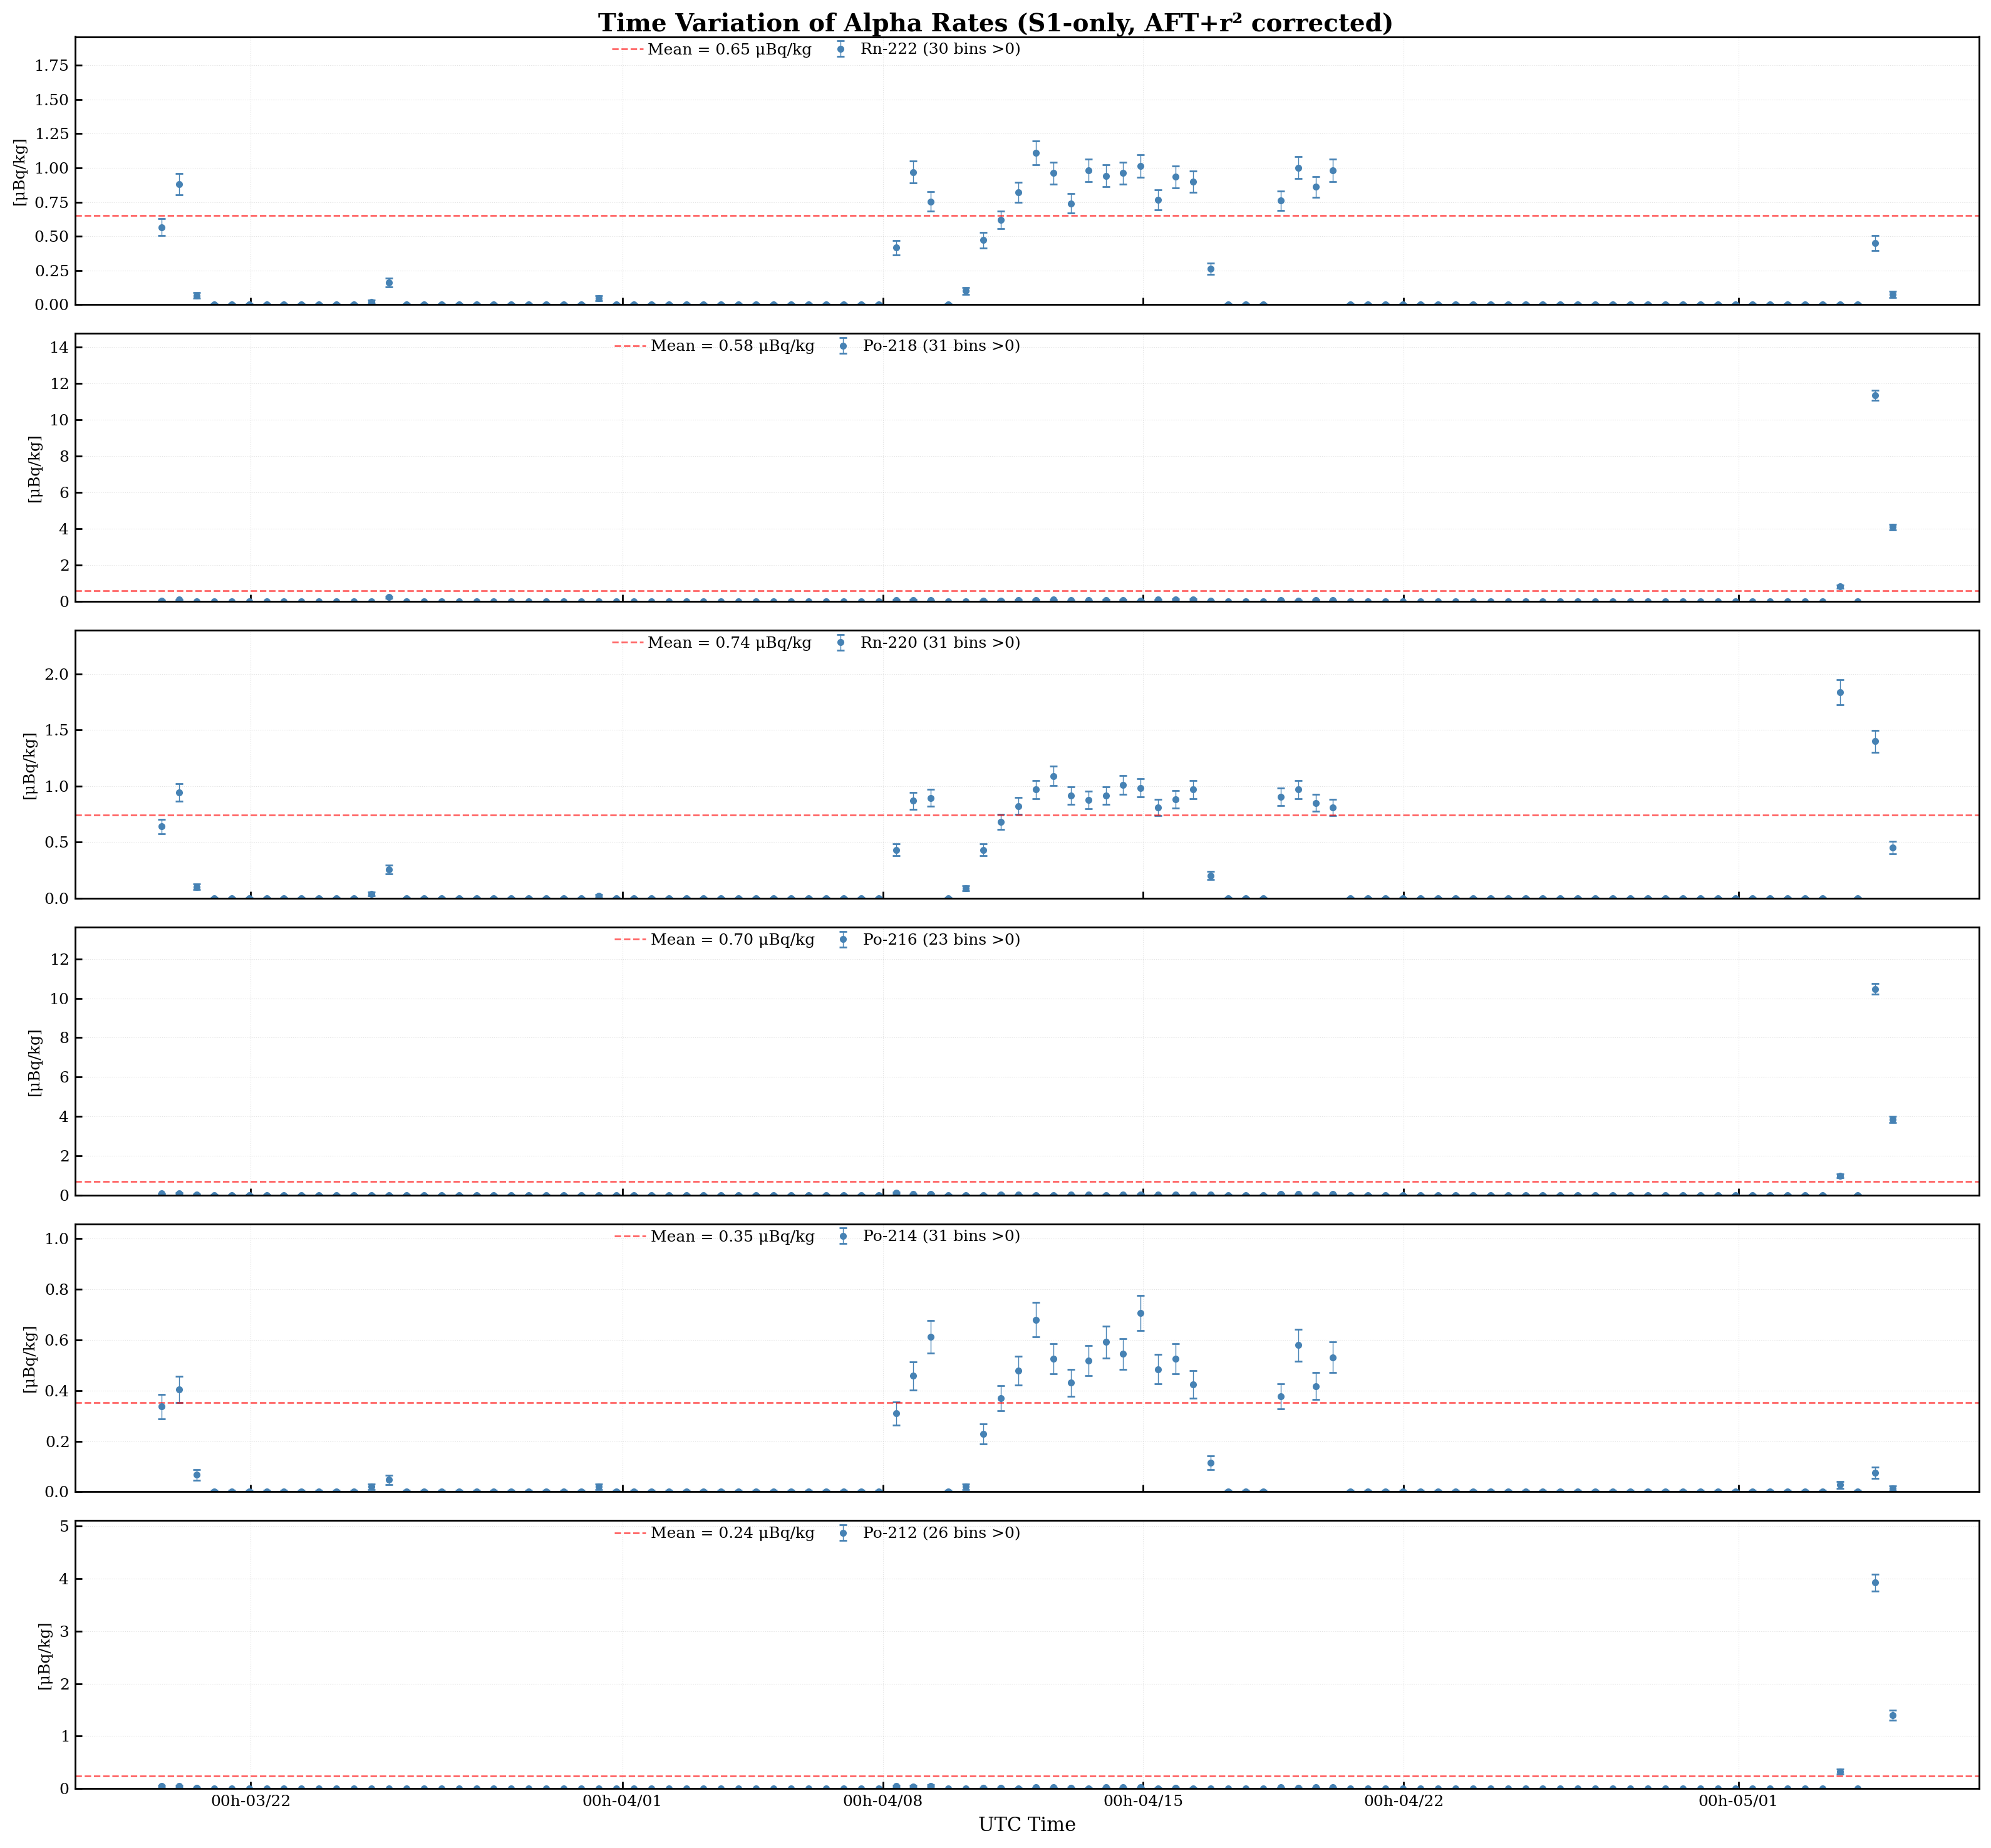


  MEAN RATES  (μBq/kg) — non-zero bins only  (100 total bins)
  Rn-222          0.65 ±   0.35 μBq/kg  (30/100 bins)
  Po-218          0.58 ±   2.09 μBq/kg  (31/100 bins)
  Rn-220          0.74 ±   0.40 μBq/kg  (31/100 bins)
  Po-216          0.70 ±   2.23 μBq/kg  (23/100 bins)
  Po-214          0.35 ±   0.22 μBq/kg  (31/100 bins)
  Po-212          0.24 ±   0.79 μBq/kg  (26/100 bins)


In [151]:
# ═══════════════════════════════════════════════════════════════
# TIME VARIATION — rate per isotope vs UTC time
# ═══════════════════════════════════════════════════════════════
# Bin events in time, count each isotope within ±3σ, convert to Bq/kg.
# Fiducial mass = 3660 kg (XENONnT TPC).

from datetime import datetime, timezone

FMASS = 3660.0  # kg
N_TIME_BINS = 100

if not fit_ok:
    print('Skipping time variation — fit did not converge.')
else:
    # ── Time binning ──
    t_ns = rn_events['time'].values
    t_start_ns = t_ns.min()
    t_end_ns   = t_ns.max()

    time_edges_ns = np.linspace(t_start_ns, t_end_ns, N_TIME_BINS + 1)
    time_centers_ns = 0.5 * (time_edges_ns[:-1] + time_edges_ns[1:])
    bin_width_s = (time_edges_ns[1] - time_edges_ns[0]) / 1e9

    # Convert to UTC datetime
    t_centers_dt = [datetime.fromtimestamp(tc / 1e9, tz=timezone.utc)
                    for tc in time_centers_ns]

    livetime_total_s = (t_end_ns - t_start_ns) / 1e9
    livetime_total_d = livetime_total_s / 86400

    print(f'Time range: {datetime.fromtimestamp(t_start_ns/1e9, tz=timezone.utc).strftime("%Y-%m-%d %H:%M")} '
          f'→ {datetime.fromtimestamp(t_end_ns/1e9, tz=timezone.utc).strftime("%Y-%m-%d %H:%M")} UTC')
    print(f'Total livetime: {livetime_total_d:.2f} days')
    print(f'{N_TIME_BINS} bins, bin width = {bin_width_s:.0f} s = {bin_width_s/3600:.2f} h')

    # ── Count events per isotope per time bin ──
    rates = {}   # rates[isotope] = array of N_bins values [Bq/kg]
    errs  = {}   # errs[isotope]  = array of N_bins values

    for i in range(N_PEAKS):
        mu  = p_fit[3*i + 1]
        sig = p_fit[3*i + 2]
        lo = mu - 3*sig
        hi = mu + 3*sig

        mask = ((rn_events['area_2_corrected'] >= lo) &
                (rn_events['area_2_corrected'] <= hi))
        t_isotope = rn_events.loc[mask, 'time'].values

        counts, _ = np.histogram(t_isotope, bins=time_edges_ns)
        # Rate = N / (Δt * M)  [Bq/kg]
        rates[PEAK_NAMES[i]] = counts / (bin_width_s * FMASS)
        errs[PEAK_NAMES[i]]  = np.sqrt(np.maximum(counts, 1)) / (bin_width_s * FMASS)

    # ── Plot ──
    fig, axes = plt.subplots(N_PEAKS, 1, figsize=(16, 2.5 * N_PEAKS), sharex=True)

    for ax, name in zip(axes, PEAK_NAMES):
        r = rates[name]
        e = errs[name]

        # Exclude zero-rate bins for the mean
        nonzero = r > 0
        n_nonzero = nonzero.sum()
        mean_rate = r[nonzero].mean() * 1e6 if n_nonzero > 0 else 0.0

        ax.errorbar(t_centers_dt, r * 1e6, yerr=e * 1e6,
                    fmt='o', color='steelblue', markersize=3,
                    capsize=2, lw=0.5, label=f'{name} ({n_nonzero} bins >0)')

        # Horizontal line at mean rate (non-zero bins only)
        ax.axhline(y=mean_rate, color='red', ls='--', lw=1, alpha=0.6,
                   label=f'Mean = {mean_rate:.2f} μBq/kg')

        ax.set_ylabel('[μBq/kg]', fontsize=9)
        ax.legend(fontsize=9, loc='upper right')
        ax.grid(True, alpha=0.3)
        ax.set_ylim(0, max(r.max() * 1e6 * 1.3, mean_rate * 3))

    # ── X-axis formatting: HHh-MM/DD UTC ──
    import matplotlib.dates as mdates
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Hh-%m/%d', tz=timezone.utc))
    ax.xaxis.set_major_locator(mdates.AutoDateLocator())
    fig.autofmt_xdate(rotation=0, ha='center')
    ax.set_xlabel('UTC Time', fontsize=11)

    fig.suptitle('Time Variation of Alpha Rates (S1-only, AFT+r² corrected)',
                 fontsize=14, fontweight='bold')
    safe_tight(fig)
    plt.show()

    # ── Print summary ──
    print(f'\n{"="*75}')
    print(f'  MEAN RATES  (μBq/kg) — non-zero bins only  ({N_TIME_BINS} total bins)')
    print(f'{"="*75}')
    for name in PEAK_NAMES:
        r = rates[name]
        nonzero = r > 0
        n_nz = nonzero.sum()
        r_mean = r[nonzero].mean() * 1e6 if n_nz > 0 else 0.0
        r_std  = r[nonzero].std() * 1e6 if n_nz > 0 else 0.0
        print(f'  {name:10s}  {r_mean:8.2f} ± {r_std:6.2f} μBq/kg  ({n_nz}/{N_TIME_BINS} bins)')
    print(f'{"="*75}')

---
## Analysis Summary

**Data:** S1-only alpha candidates from SR3 commissioning runs.

**Pre-correction cuts:**
1. Pulse width [40, 200] ns — S1 pulse shape selection
2. r² < 3800 cm² — TPC wall rejection

**Corrections (in order):**
1. **Area vs AFT** — Two-step: (a) initial fit with manual exp_bump_model boundaries, (b) refine selection to vertical band (±1σ) in area_aft_corrected, re-fit centerline, normalize to AFT=0.30 → `area_aft_corrected`. Rn band tagged as vertical cut in corrected space → `in_rn_band`
2. **AFT vs r²** — r²(AFT) degree-N polynomial fitted on Rn-band events, r² corrected to reference AFT → `r2_aft_corrected`
3. **r² vs Area** — band selected with linear boundaries (k=-120) in r2_aft_corrected vs area_aft_corrected space, degree-5 polynomial fit (r²<60), area corrected to r²=0 → `area_2_corrected`

**Post-correction cuts:**
- AFT fiducial [0.12, 0.55] — BiPo + gas band rejection
- FV cut [AFT 0.17–0.43, r² < 40 cm²] — tight fiducial volume

**Rate measurement:**
- Multi-Gaussian fit to AFT+r²-corrected 1D spectrum using ALL events after cuts
- 6 peaks: Rn-222, Po-218, Rn-220, Po-216, Po-214, Po-212
- Events counted within ±3σ window per peak

**Key DataFrames:**
- `df_cut` — after pre-correction cuts (full AFT range)
- `d_cor` — with all correction columns (`area_aft_corrected`, `r2_aft_corrected`, `area_2_corrected`, `in_rn_band`)
- `d_cor_aft` — after post-correction AFT+FV cuts, used for rate calculation